Importing libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/raw/European_Bank.csv')

Analysing the given data

In [4]:
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.describe()

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [6]:
df.shape

(10000, 14)

In [7]:
df.isnull().sum()

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender',
       'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

## 1. Data Quality Assessment

In this section, we examine the dataset for missing values, duplicate records, inconsistent data types, and invalid values.

In [10]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Count,Missing Percentage
Year,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


In [11]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


Number of unique values in Columns

In [12]:
df.nunique().sort_values(ascending=False)

CustomerId         10000
EstimatedSalary     9999
Balance             6382
Surname             2932
CreditScore          460
Age                   70
Tenure                11
NumOfProducts          4
Geography              3
Gender                 2
IsActiveMember         2
HasCrCard              2
Exited                 2
Year                   1
dtype: int64

Checking Categorical Column

In [13]:
categorical_columns = df.select_dtypes(
    include=["str", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


Surname:
Surname
Smith        32
Scott        29
Martin       29
Walker       28
Brown        26
             ..
Salinas       1
Cleveland     1
Kashiwagi     1
Aldridge      1
Burbidge      1
Name: count, Length: 2932, dtype: int64

Geography:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender:
Gender
Male      5457
Female    4543
Name: count, dtype: int64


checking numerical column

In [14]:
df.select_dtypes(include=np.number).describe().T

,count,mean,std,min,25%,50%,75%,max
Year,10000.0,2.025000e+03,0.000000,2025.00,2025.00,2.025000e+03,2.025000e+03,2025.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


## 2. Data validation and consistency

In [15]:
# Check categorical values
for column in ["Geography", "Gender"]:
    print(f"\n{column}:")
    print(df[column].value_counts())

# Check binary columns
binary_columns = ["HasCrCard", "IsActiveMember", "Exited"]

for column in binary_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


Geography:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender:
Gender
Male      5457
Female    4543
Name: count, dtype: int64

HasCrCard:
HasCrCard
1    7055
0    2945
Name: count, dtype: int64

IsActiveMember:
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

Exited:
Exited
0    7963
1    2037
Name: count, dtype: int64


 Validate numerical ranges

In [16]:
numerical_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

range_summary = pd.DataFrame({
    "Minimum": df[numerical_columns].min(),
    "Maximum": df[numerical_columns].max(),
    "Unique Values": df[numerical_columns].nunique()
})

range_summary

,Minimum,Maximum,Unique Values
CreditScore,350.00,850.00,460
Age,18.00,92.00,70
Tenure,0.00,10.00,11
Balance,0.00,250898.09,6382
NumOfProducts,1.00,4.00,4
EstimatedSalary,11.58,199992.48,9999


## 3. Check invalid records

In [17]:
validation_checks = {
    "Invalid Credit Scores": (~df["CreditScore"].between(300, 900)).sum(),
    "Invalid Ages": (df["Age"] < 18).sum(),
    "Invalid Tenure": (~df["Tenure"].between(0, 10)).sum(),
    "Invalid Product Counts": (~df["NumOfProducts"].between(1, 4)).sum(),
    "Invalid Binary Values": (
        (~df["HasCrCard"].isin([0, 1])) |
        (~df["IsActiveMember"].isin([0, 1])) |
        (~df["Exited"].isin([0, 1]))
    ).sum()
}

pd.Series(validation_checks, name="Invalid Records")

Invalid Credit Scores     0
Invalid Ages              0
Invalid Tenure            0
Invalid Product Counts    0
Invalid Binary Values     0
Name: Invalid Records, dtype: int64

##  Data Validation Findings

### 1. Categorical Values
- Geography contains three categories: France (5,014), Germany (2,509), and Spain (2,477).
- Gender contains Male (5,457) and Female (4,543).
- No missing categorical values were detected.

### 2. Binary Variables
- HasCrCard: 7,055 customers have a credit card and 2,945 do not.
- IsActiveMember: 5,151 customers are active and 4,849 are inactive.
- Exited: 7,963 customers were retained and 2,037 exited.
- All binary columns contain only 0 and 1.

### 3. Numerical Ranges
- CreditScore: 350–850.
- Age: 18–92 years.
- Tenure: 0–10 years.
- Balance: 0–250898.09.
- NumOfProducts: 1–4.
- EstimatedSalary: 11.58–199992.48.

### 4. Numerical Validation Results

The following validation checks were performed:

| Validation Check | Invalid Records |
|---|---:|
| Credit Score | 0 |
| Age | 0 |
| Tenure | 0 |
| Product Count | 0 |
| Binary Variables | 0 |

All numerical and binary fields passed the defined validation checks.

### 5. Conclusion

The dataset contains 10,000 records and 14 columns, with no missing values or duplicate rows. All categorical and binary values were found within the expected categories, and all numerical validation checks returned zero invalid records.

The dataset is suitable for proceeding to exploratory data analysis (EDA), subject to further investigation of business-specific assumptions and potential anomalies.


# 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand customer characteristics, identify patterns, examine relationships between variables, and discover factors associated with customer churn.

The analysis focuses on customer demographics, engagement, product utilization, and financial characteristics.

# Analysis 1 — Overall customer churn distribution

In [18]:
# Calculate customer retention and churn counts
churn_counts = df["Exited"].value_counts().sort_index()

# Calculate percentages
churn_percentage = df["Exited"].value_counts(normalize=True).sort_index() * 100

churn_summary = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage": churn_percentage
})

churn_summary.index = ["Retained", "Exited"]

churn_summary

,Customer Count,Percentage
Retained,7963,79.63
Exited,2037,20.37


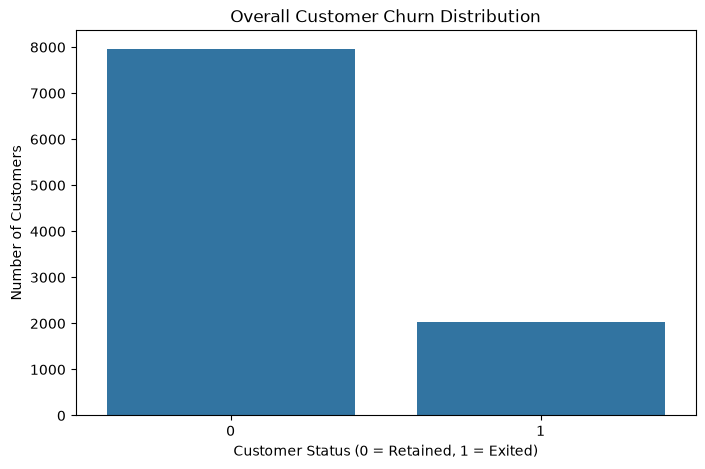

In [19]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Exited")

plt.title("Overall Customer Churn Distribution")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Number of Customers")

plt.show()


# Analysis 2 — Customer demographics

A. Churn by geography

In [20]:

geography_churn = df.groupby("Geography")["Exited"].mean() * 100

geography_churn.sort_values(ascending=False)


Geography
Germany    32.443204
Spain      16.673395
France     16.154767
Name: Exited, dtype: float64

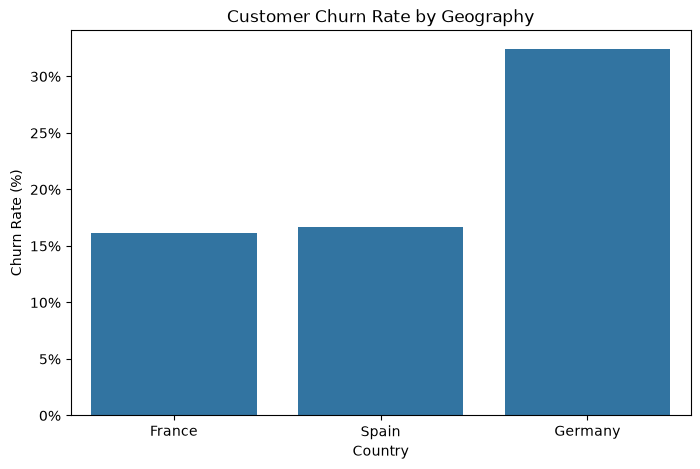

In [21]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Geography",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


B. Churn by gender

In [22]:
gender_churn = df.groupby("Gender")["Exited"].mean() * 100

gender_churn


Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64

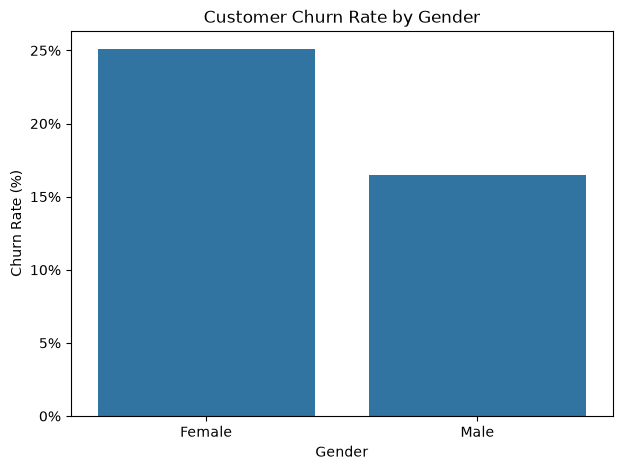

In [23]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Gender",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


# Analysis 3 — Customer engagement

In [24]:
activity_churn = (
    df.groupby("IsActiveMember")["Exited"].mean() * 100
)


activity_churn.index = ["Inactive", "Active"]

activity_churn


Inactive    26.850897
Active      14.269074
Name: Exited, dtype: float64

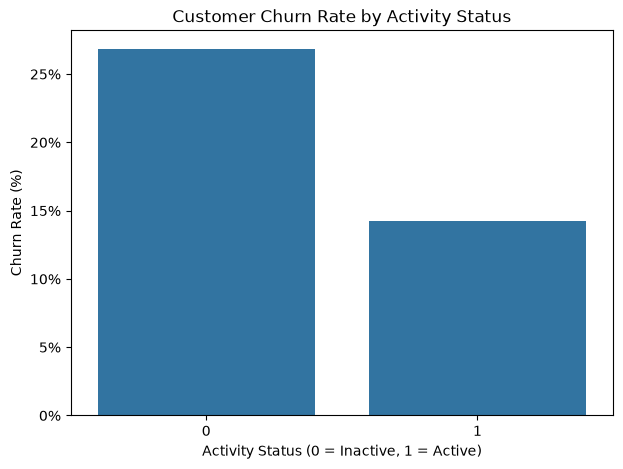

In [25]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="IsActiveMember",
    y="Exited",
    errorbar=None
)

plt.title("Customer Churn Rate by Activity Status")
plt.xlabel("Activity Status (0 = Inactive, 1 = Active)")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


# Analysis 4 — Product utilization

In [26]:
# Calculate customer count and churn rate for each product group
product_analysis = df.groupby("NumOfProducts").agg(
    Customer_Count=("CustomerId", "count"),
    Churn_Rate=("Exited", "mean")
)

# Convert churn rate into percentage
product_analysis["Churn_Rate"] *= 100

product_analysis


,Customer_Count,Churn_Rate
NumOfProducts,,
1,5084,27.714398
2,4590,7.581699
3,266,82.706767
4,60,100.000000


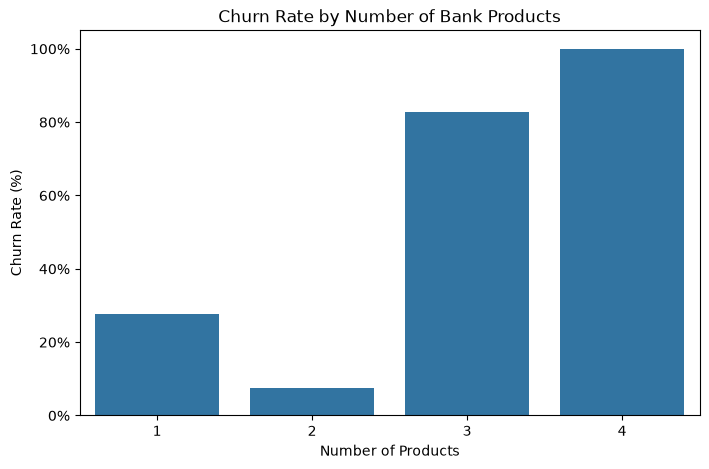

In [27]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="NumOfProducts",
    y="Exited",
    errorbar=None
)

plt.title("Churn Rate by Number of Bank Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
)

plt.show()


# Analysis 5 — Financial characteristics

A. Balance distribution by churn

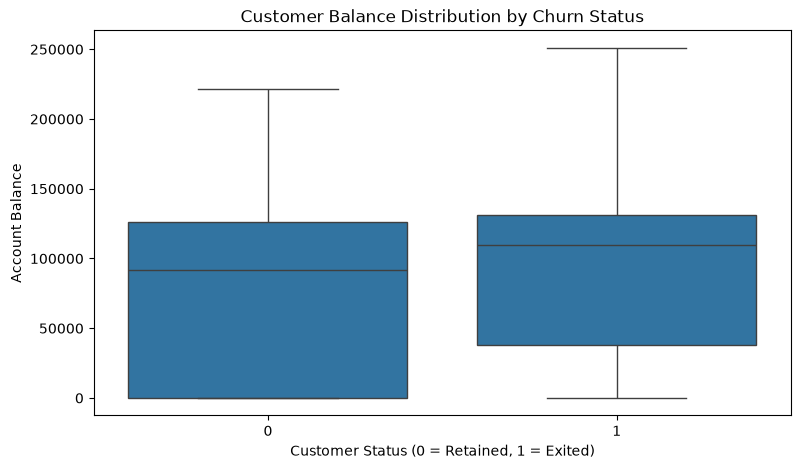

In [28]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Balance"
)

plt.title("Customer Balance Distribution by Churn Status")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Account Balance")

plt.show()


B. Salary distribution by churn

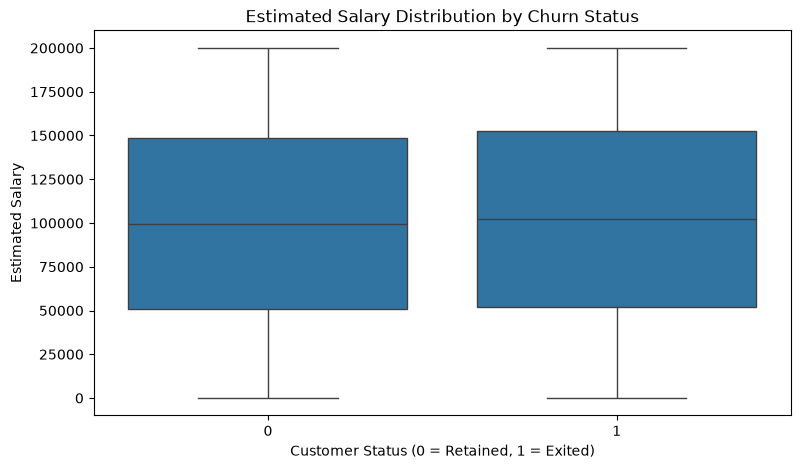

In [29]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="EstimatedSalary"
)

plt.title("Estimated Salary Distribution by Churn Status")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Estimated Salary")

plt.show()


# Analysis 6 — Age and churn

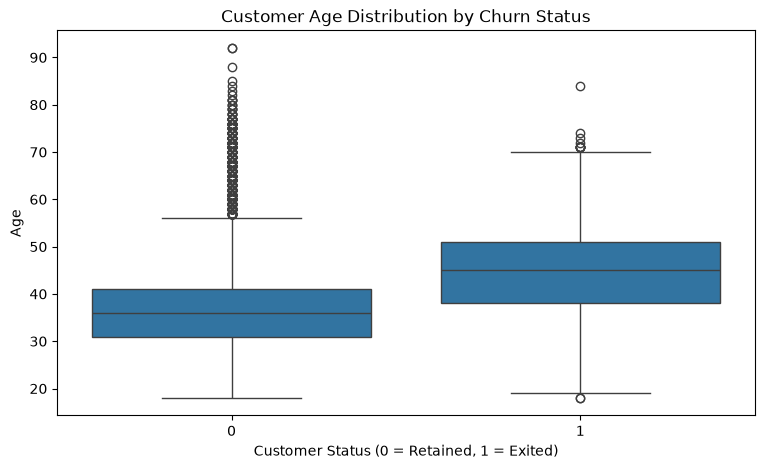

In [30]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Age"
)

plt.title("Customer Age Distribution by Churn Status")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Age")

plt.show()


In [31]:

# Examine the number of customers in each product group
product_group_summary = df.groupby("NumOfProducts").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum"),
    Retained_Customers=("Exited", lambda x: (x == 0).sum()),
    Churn_Rate=("Exited", "mean")
)

product_group_summary["Churn_Rate"] *= 100

product_group_summary


,Total_Customers,Exited_Customers,Retained_Customers,Churn_Rate
NumOfProducts,,,,
1,5084,1409,3675,27.714398
2,4590,348,4242,7.581699
3,266,220,46,82.706767
4,60,60,0,100.000000


In [32]:

# Compare customer churn across product count and activity status
product_activity_analysis = df.pivot_table(
    index="NumOfProducts",
    columns="IsActiveMember",
    values="Exited",
    aggfunc="mean"
) * 100

# Give activity columns readable names
product_activity_analysis.columns = ["Inactive", "Active"]

product_activity_analysis


,Inactive,Active
NumOfProducts,,
1,36.652122,18.923137
2,9.888060,5.560098
3,88.235294,75.221239
4,100.000000,100.000000



#  Exploratory Data Analysis Findings

## 1 Overall Customer Churn Distribution

The dataset contains 10,000 customers, of which 7,963 (79.63%) were retained and 2,037 (20.37%) exited.

The overall customer churn rate is 20.37%, indicating that approximately one in five customers left the bank.

## 2 Geography and Customer Churn

Germany recorded the highest churn rate at approximately 32.4%, followed by Spain at 16.7% and France at 16.2%.

This indicates geographical differences in customer retention patterns. Germany represents an important area for further investigation and targeted retention strategies.

## 3 Gender and Customer Churn

Female customers recorded an approximate churn rate of 25.1%, compared with 16.4% among male customers.

This indicates differences in observed churn patterns between gender groups. Further investigation is required to understand the underlying customer behaviour.

## 4 Customer Engagement and Churn

Inactive customers recorded an approximate churn rate of 26.9%, compared with 14.3% among active customers.

This suggests that customer activity is associated with retention. Inactive customers may require additional engagement initiatives to reduce potential churn.

## 5 Product Utilization and Customer Churn

The relationship between the number of bank products and customer churn revealed the following:

| Product Count | Customers | Exited | Retained | Churn Rate |
|---|---:|---:|---:|---:|
| 1 | 5,084 | 1,409 | 3,675 | 27.71% |
| 2 | 4,590 | 348 | 4,242 | 7.58% |
| 3 | 266 | 220 | 46 | 82.71% |
| 4 | 60 | 60 | 0 | 100.00% |

Customers holding two products demonstrated the lowest observed churn rate.

However, customers holding three and four products showed substantially higher churn rates. The smaller sample sizes of these groups should be considered when interpreting the results.

## 6 Product Utilization and Customer Engagement

A combined analysis of product count and customer activity revealed:

| Product Count | Inactive Churn (%) | Active Churn (%) |
|---|---:|---:|
| 1 | 36.65 | 18.92 |
| 2 | 9.89 | 5.56 |
| 3 | 88.24 | 75.22 |
| 4 | 100.00 | 100.00 |

Inactive customers showed higher churn rates than active customers across the first three product groups.

For customers holding four products, both activity groups recorded 100% churn.

These findings suggest that customer engagement and product utilization should be examined together when evaluating retention.

## 7 Financial Characteristics and Customer Churn

The account balance comparison showed that exited customers had a higher median balance than retained customers.

However, estimated salary distributions were broadly similar between retained and exited customers.

These observations suggest that financial characteristics alone may not adequately explain customer retention.

High-balance customers who are inactive require further investigation.

## 8 Age and Customer Churn

The age distribution analysis showed that exited customers generally had a higher median age than retained customers.

The median age was approximately 45 years for exited customers and 36 years for retained customers.

This suggests an association between customer age and churn behaviour.

## 9 Overall EDA Observations

The exploratory analysis identified several important patterns:

1. The overall churn rate is 20.37%.
2. Germany recorded the highest geographical churn rate.
3. Female customers showed a higher observed churn rate than male customers.
4. Inactive customers demonstrated higher churn than active customers.
5. Customers holding two products recorded the lowest observed churn rate.
6. Customers with three and four products showed unusually high churn rates.
7. Exited customers had higher median account balances.
8. Estimated salary distributions were broadly similar across churn groups.
9. Exited customers generally had a higher median age.

## 10 Business Implications

Based on the exploratory findings, the following areas require further investigation:

- Improve engagement initiatives for inactive customers.
- Investigate customer retention patterns in Germany.
- Examine why customers holding three and four products have unusually high churn rates.
- Identify high-balance customers who are inactive.
- Evaluate product adoption and relationship depth alongside customer activity.
- Develop targeted retention strategies based on customer behaviour.

## 11 Limitations

The analysis identifies associations and does not establish causal relationships.

Some customer segments, particularly those holding four products, contain relatively few observations. Their churn rates should therefore be interpreted cautiously.

Further segmentation and statistical analysis are required before making final business recommendations.
vvv


## 5. High-Value Disengaged Customer Analysis

This analysis identifies inactive customers with above-median account balances and examines their retention status.

In [33]:
median_balance = df["Balance"].median()

print("Median Balance:", median_balance)


Median Balance: 97198.54000000001


5.1 Identify high-balance inactive customers

In [34]:

high_balance_inactive = df[
    (df["Balance"] > median_balance) &
    (df["IsActiveMember"] == 0)
]

print("High-balance inactive customers:", len(high_balance_inactive))


High-balance inactive customers: 2456


5.2 Separate retained and exited customers

In [35]:

risk_status = high_balance_inactive["Exited"].value_counts()


risk_percentage = (
    high_balance_inactive["Exited"]
    .value_counts(normalize=True) * 100
)

risk_summary = pd.DataFrame({
    "Customer Count": risk_status,
    "Percentage": risk_percentage
})

risk_summary.index = ["Retained", "Exited"]

risk_summary


,Customer Count,Percentage
Retained,1662,67.67101
Exited,794,32.32899


5.3 Compare high-balance customers by activity and churn

In [36]:
balance_activity_analysis = df.pivot_table(
    index="IsActiveMember",
    columns="Exited",
    values="Balance",
    aggfunc="count"
)

balance_activity_analysis.index = ["Inactive", "Active"]
balance_activity_analysis.columns = ["Retained", "Exited"]

balance_activity_analysis


,Retained,Exited
Inactive,3547,1302
Active,4416,735


5.4 Compare average account balances across customer groups

In [37]:
\
average_balance_analysis = df.groupby(
    ["IsActiveMember", "Exited"]
)["Balance"].mean().unstack()

average_balance_analysis.index = ["Inactive", "Active"]
average_balance_analysis.columns = ["Retained", "Exited"]

average_balance_analysis


,Retained,Exited
Inactive,72048.820578,90988.807081
Active,73304.717314,91320.636476


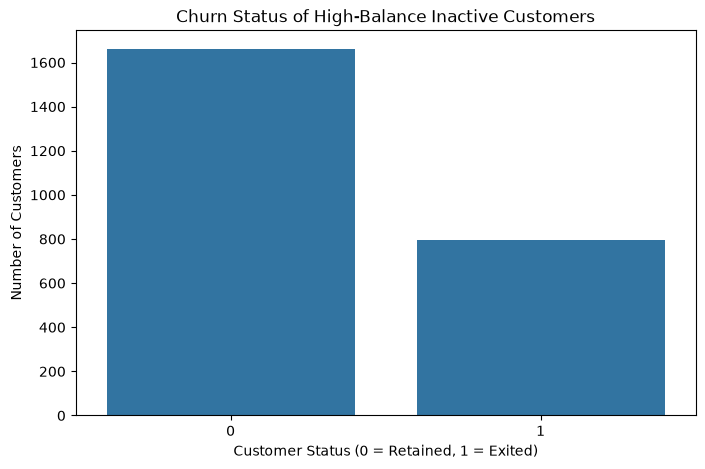

In [38]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=high_balance_inactive,
    x="Exited"
)

plt.title("Churn Status of High-Balance Inactive Customers")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Number of Customers")

plt.show()



##  High-Value Disengaged Customer Findings

The median account balance was 97,198.54. Using this as the preliminary threshold, 2,456 customers were identified as having above-median balances and inactive membership.

- Retained customers: 1,662 (67.67%).
- Exited customers: 794 (32.33%).

Exited customers also showed higher average balances than retained customers across both activity groups.

### Business Observation

A considerable number of high-balance inactive customers remain with the bank and may be suitable targets for engagement-based retention initiatives.

Account balance and activity should be evaluated together when identifying potentially at-risk customers.

### Limitation

Above-median balance is a preliminary proxy for customer value, not a complete measure of customer profitability or wealth.


## 6. Customer Engagement Classification.

The objective is to divide customers into the four engagement categories specified in your Unified Mentor assignment.

6.1 Create customer segments

In [39]:

# Define conditions for each customer segment
conditions = [
    (df["IsActiveMember"] == 0) & (df["Balance"] > median_balance),

    (df["IsActiveMember"] == 1) & (df["NumOfProducts"] == 1),

    (df["IsActiveMember"] == 1) & (df["NumOfProducts"] > 1),

    (df["IsActiveMember"] == 0)
]

# Assign a segment to each customer
segments = [
    "Inactive High-Balance",
    "Active but Low-Product",
    "Active Engaged",
    "Inactive Disengaged"
]

df["Engagement_Segment"] = np.select(
    conditions,
    segments,
    default="Unclassified"
)

df["Engagement_Segment"].value_counts()


Engagement_Segment
Active Engaged            2588
Active but Low-Product    2563
Inactive High-Balance     2456
Inactive Disengaged       2393
Name: count, dtype: int64

6.2 Analyze churn by engagement segment

In [40]:

# Calculate customer count and churn rate by engagement segment
engagement_summary = df.groupby("Engagement_Segment").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

# Convert churn rate into percentage
engagement_summary["Churn_Rate"] *= 100

engagement_summary.sort_values(
    by="Churn_Rate",
    ascending=False
)


,Total_Customers,Exited_Customers,Churn_Rate
Engagement_Segment,,,
Inactive High-Balance,2456,794,32.328990
Inactive Disengaged,2393,508,21.228583
Active but Low-Product,2563,485,18.923137
Active Engaged,2588,250,9.659969


6.3 Visualize customer segments

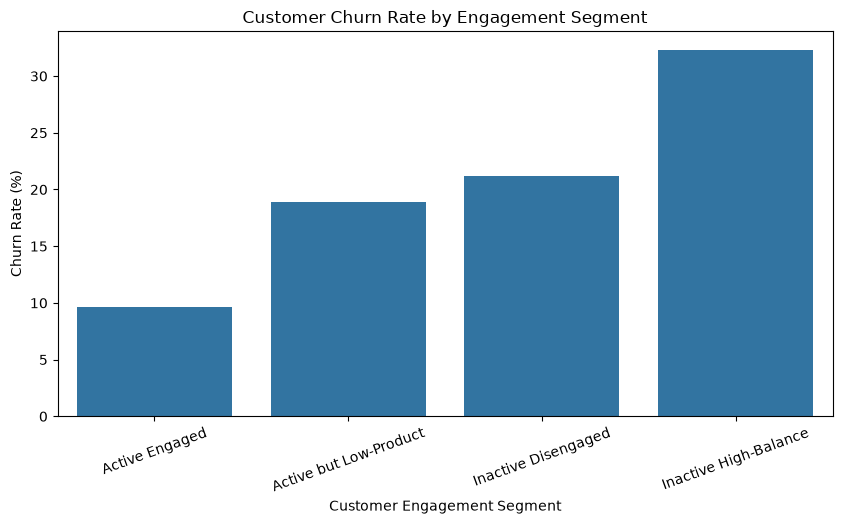

In [41]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=engagement_summary.reset_index(),
    x="Engagement_Segment",
    y="Churn_Rate"
)

plt.title("Customer Churn Rate by Engagement Segment")
plt.xlabel("Customer Engagement Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

plt.show()


### 6.5 Document Your Findings

The engagement analysis identified the following important findings:

| Customer Segment | Churn Rate | Interpretation |
|---|---:|---|
| Inactive High-Balance | 32.33% | Highest churn risk; these customers need priority attention. |
| Inactive Disengaged | 21.23% | Churn is slightly above the overall rate. |
| Active but Low-Product | 18.92% | Opportunity to improve product adoption. |
| Active Engaged | 9.66% | Lowest churn rate and comparatively stronger retention. |

**Key Observations:**

- Inactive high-balance customers have the highest churn rate (32.33%).
- Inactive disengaged customers also show a relatively high churn rate (21.23%).
- Active but low-product customers may benefit from suitable additional product offerings.
- Active engaged customers have the lowest churn rate (9.66%).
- Customer activity and product adoption are associated with differences in churn rates.

**Conclusion:**

Customer engagement plays an important role in understanding retention patterns. The analysis suggests that retention efforts should prioritize inactive high-balance customers and encourage stronger engagement among inactive customers.

## 7. Product Utilization Analysis

Product utilization analysis examines how the number of products held by customers relates to retention and churn. It helps identify differences between single-product and multi-product customers and highlights potential opportunities to improve product adoption.

In [42]:
product_distribution = df["NumOfProducts"].value_counts().sort_index()

product_distribution

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

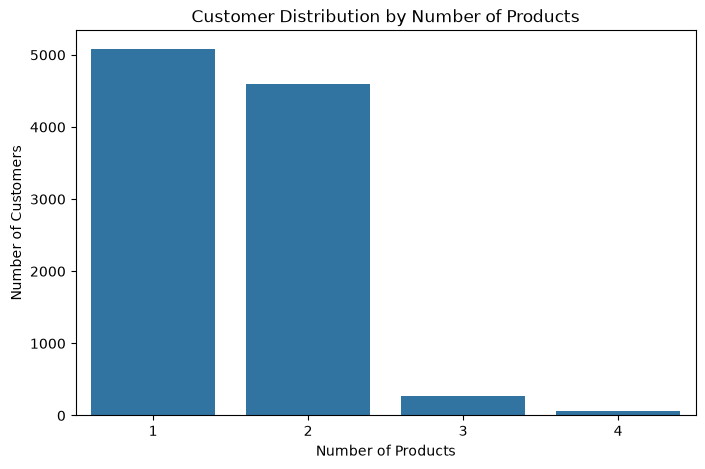

In [43]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="NumOfProducts")

plt.title("Customer Distribution by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Number of Customers")

plt.show()

### 7.2 Churn Rate by Number of Products

Customer churn rates were compared across different product-count groups to examine whether product adoption is associated with customer retention.

In [44]:
product_churn = df.groupby("NumOfProducts").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

product_churn["Churn_Rate"] *= 100

product_churn

,Total_Customers,Exited_Customers,Churn_Rate
NumOfProducts,,,
1,5084,1409,27.714398
2,4590,348,7.581699
3,266,220,82.706767
4,60,60,100.000000


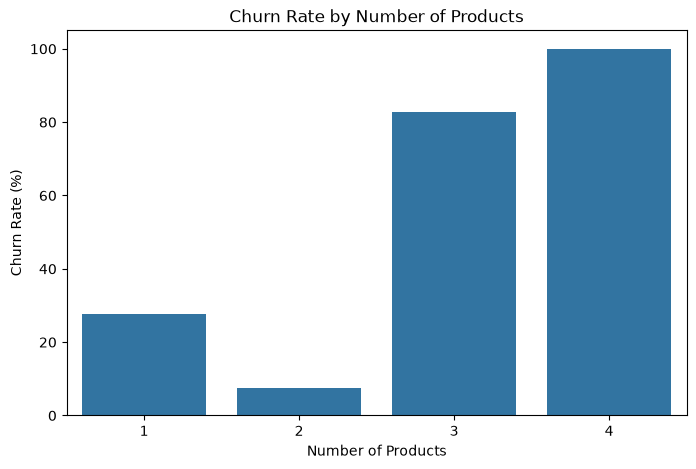

In [45]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=product_churn.reset_index(),
    x="NumOfProducts",
    y="Churn_Rate"
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.show()

### 7.3 Single-Product vs Multi-Product Customers

Customers were divided into single-product and multi-product groups to compare their retention patterns. This comparison helps assess whether broader product adoption is associated with lower churn.

In [46]:
df["Product_Category"] = np.where(
    df["NumOfProducts"] == 1,
    "Single-Product",
    "Multi-Product"
)

product_category_summary = df.groupby("Product_Category").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

product_category_summary["Churn_Rate"] *= 100

product_category_summary

,Total_Customers,Exited_Customers,Churn_Rate
Product_Category,,,
Multi-Product,4916,628,12.774614
Single-Product,5084,1409,27.714398


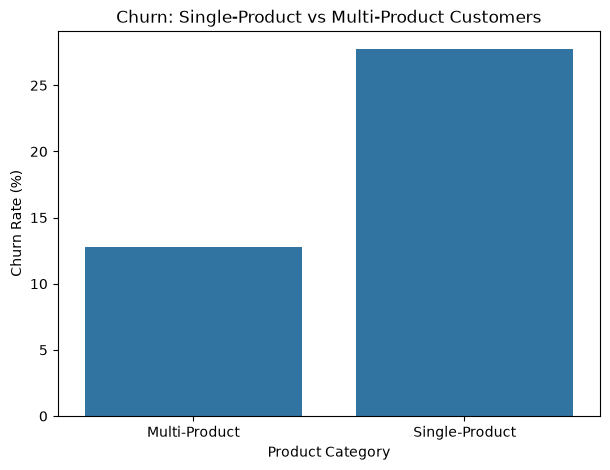

In [47]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=product_category_summary.reset_index(),
    x="Product_Category",
    y="Churn_Rate"
)

plt.title("Churn: Single-Product vs Multi-Product Customers")
plt.xlabel("Product Category")
plt.ylabel("Churn Rate (%)")

plt.show()

### 7.4 Product Depth Analysis

Product depth measures the number of products held by each customer. The average product count provides an overview of customer product adoption and helps compare the product relationships of retained and exited customers.

In [48]:
product_depth_summary = df.groupby("Exited").agg(
    Total_Customers=("CustomerId", "count"),
    Average_Products=("NumOfProducts", "mean"),
    Median_Products=("NumOfProducts", "median")
)

product_depth_summary.index = product_depth_summary.index.map({
    0: "Retained",
    1: "Exited"
})

product_depth_summary

,Total_Customers,Average_Products,Median_Products
Exited,,,
Retained,7963,1.544267,2.0
Exited,2037,1.475209,1.0


### 7.5 Product Utilization Metrics

The following indicators summarize customer product adoption:

- Multi-Product Adoption Rate measures the percentage of customers holding more than one product.
- Average Product Depth measures the average number of products held per customer.

These indicators provide a simple overview of product utilization across the customer base.

In [49]:
total_customers = len(df)

multi_product_customers = (df["NumOfProducts"] > 1).sum()

multi_product_adoption_rate = (
    multi_product_customers / total_customers
) * 100

average_product_depth = df["NumOfProducts"].mean()

print(f"Multi-Product Adoption Rate: {multi_product_adoption_rate:.2f}%")
print(f"Average Product Depth: {average_product_depth:.2f}")

Multi-Product Adoption Rate: 49.16%
Average Product Depth: 1.53


### 7.6 Documenting my Findings

The product utilization analysis examined customer distribution, churn rates, product adoption, and average product depth.

**Product Utilization Summary**

| Metric | Result | Interpretation |
|---|---:|---|
| Single-Product Customers | 5,084 (50.84%) | More than half of customers hold one product. |
| Multi-Product Customers | 4,916 (49.16%) | Nearly half of customers hold multiple products. |
| Average Product Depth | 1.53 | Customers hold approximately 1.53 products on average. |
| Lowest Churn Rate | 7.58% | Observed among two-product customers. |
| Highest Churn Rate | 100.00% | Observed among four-product customers (60 customers). |

**Key Observations**

- Single-product customers recorded a churn rate of 27.71%, compared with 12.77% for multi-product customers.
- Two-product customers had the lowest churn rate at 7.58%, suggesting a positive association between this product count and retention.
- Three-product customers recorded an 82.71% churn rate, while four-product customers recorded 100%.
- The three-product and four-product groups contain only 266 and 60 customers respectively. Their high churn rates should therefore be interpreted cautiously.
- Retained customers held an average of 1.54 products, compared with 1.48 products among exited customers.
- The multi-product adoption rate was 49.16%, and the overall average product depth was 1.53.

**Business Implications**

- Investigate suitable additional product offerings for single-product customers to improve product adoption.
- Study the characteristics and product usage patterns of two-product customers, who recorded the lowest churn rate.
- Investigate why customers with three or four products have unusually high churn rather than assuming that more products always improve retention.
- Consider product suitability and customer needs before recommending additional products.

**Conclusion**

The analysis indicates that product utilization is associated with customer retention. Two-product customers demonstrated the lowest churn rate, while single-product customers had a considerably higher churn rate. However, the unusually high churn among customers holding three or four products shows that product count alone cannot explain customer retention. Product suitability, customer activity, and other customer characteristics should also be considered when developing retention strategies.

## 8. Financial and Engagement Analysis

This section examines the relationship between customer financial characteristics, engagement, and churn. Account balance and estimated salary are analyzed to identify financial patterns that may help explain customer retention and disengagement.

### 8.1 Account Balance by Customer Activity

Customer account balances are compared across active and inactive customers to examine whether account balances differ according to engagement status.

In [52]:
balance_activity = df.groupby("IsActiveMember").agg(
    Total_Customers=("CustomerId", "count"),
    Average_Balance=("Balance", "mean"),
    Median_Balance=("Balance", "median")
)

balance_activity.index = balance_activity.index.map({
    0: "Inactive",
    1: "Active"
})

balance_activity

,Total_Customers,Average_Balance,Median_Balance
IsActiveMember,,,
Inactive,4849,77134.376863,98263.46
Active,5151,75875.422145,96166.88


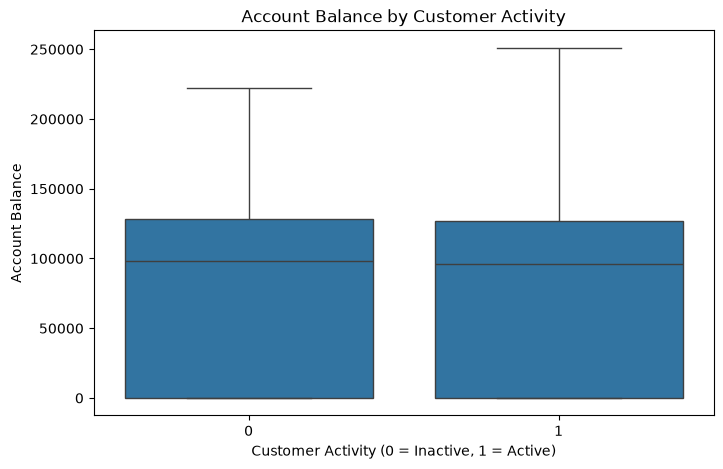

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="IsActiveMember",
    y="Balance"
)

plt.title("Account Balance by Customer Activity")
plt.xlabel("Customer Activity (0 = Inactive, 1 = Active)")
plt.ylabel("Account Balance")

plt.show()

### 8.2 Account Balance and Customer Churn

Account balances are compared between retained and exited customers to examine whether financial characteristics differ between the two groups.

In [54]:
balance_churn = df.groupby("Exited").agg(
    Total_Customers=("CustomerId", "count"),
    Average_Balance=("Balance", "mean"),
    Median_Balance=("Balance", "median")
)

balance_churn.index = balance_churn.index.map({
    0: "Retained",
    1: "Exited"
})

balance_churn

,Total_Customers,Average_Balance,Median_Balance
Exited,,,
Retained,7963,72745.296779,92072.68
Exited,2037,91108.539337,109349.29


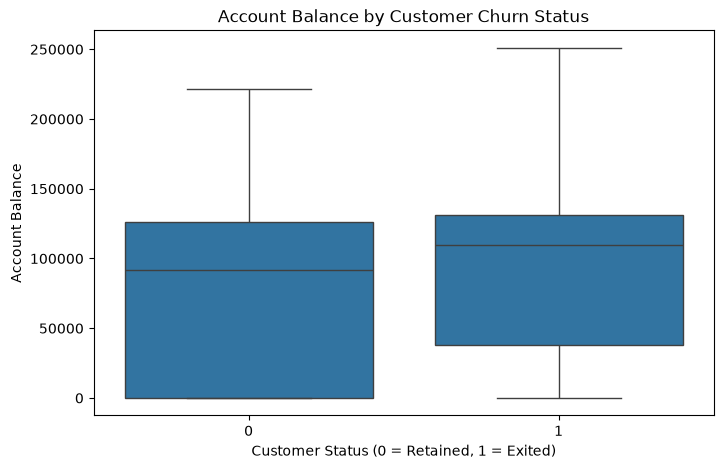

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Balance"
)

plt.title("Account Balance by Customer Churn Status")
plt.xlabel("Customer Status (0 = Retained, 1 = Exited)")
plt.ylabel("Account Balance")

plt.show()

### 8.3 Estimated Salary and Account Balance Analysis

Estimated salary and account balance are examined together to understand their relationship and identify differences in financial patterns between retained and exited customers.

In [56]:
financial_summary = df.groupby("Exited").agg(
    Total_Customers=("CustomerId", "count"),
    Average_Salary=("EstimatedSalary", "mean"),
    Average_Balance=("Balance", "mean")
)

financial_summary.index = financial_summary.index.map({
    0: "Retained",
    1: "Exited"
})

financial_summary

,Total_Customers,Average_Salary,Average_Balance
Exited,,,
Retained,7963,99738.391772,72745.296779
Exited,2037,101465.677531,91108.539337


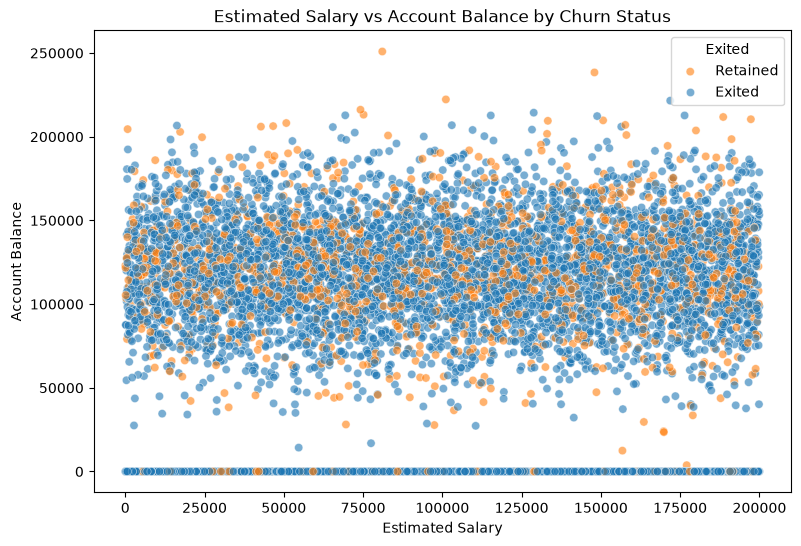

In [57]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="EstimatedSalary",
    y="Balance",
    hue="Exited",
    alpha=0.6
)

plt.title("Estimated Salary vs Account Balance by Churn Status")
plt.xlabel("Estimated Salary")
plt.ylabel("Account Balance")
plt.legend(title="Exited", labels=["Retained", "Exited"])

plt.show()

In [58]:
financial_correlation = df[
    ["EstimatedSalary", "Balance"]
].corr()

financial_correlation

,EstimatedSalary,Balance
EstimatedSalary,1.000000,0.012797
Balance,0.012797,1.000000


### 8.4 Financial Profile Classification

Customers are classified using median account balance and median estimated salary. This comparison helps identify different financial profiles, including customers with relatively high balances but lower estimated salaries.

These categories are analytical comparisons, not formal measures of wealth or financial health.

In [59]:
median_salary = df["EstimatedSalary"].median()
median_balance = df["Balance"].median()

conditions = [
    (df["Balance"] > median_balance) &
    (df["EstimatedSalary"] > median_salary),

    (df["Balance"] > median_balance) &
    (df["EstimatedSalary"] <= median_salary),

    (df["Balance"] <= median_balance) &
    (df["EstimatedSalary"] > median_salary),

    (df["Balance"] <= median_balance) &
    (df["EstimatedSalary"] <= median_salary)
]

profiles = [
    "High Balance - High Salary",
    "High Balance - Low Salary",
    "Low Balance - High Salary",
    "Low Balance - Low Salary"
]

df["Financial_Profile"] = np.select(
    conditions,
    profiles,
    default="Unclassified"
)

financial_profile_summary = df.groupby("Financial_Profile").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

financial_profile_summary["Churn_Rate"] *= 100

financial_profile_summary.sort_values(
    "Churn_Rate",
    ascending=False
)

,Total_Customers,Exited_Customers,Churn_Rate
Financial_Profile,,,
High Balance - High Salary,2516,631,25.079491
High Balance - Low Salary,2484,618,24.879227
Low Balance - High Salary,2484,411,16.545894
Low Balance - Low Salary,2516,377,14.984102


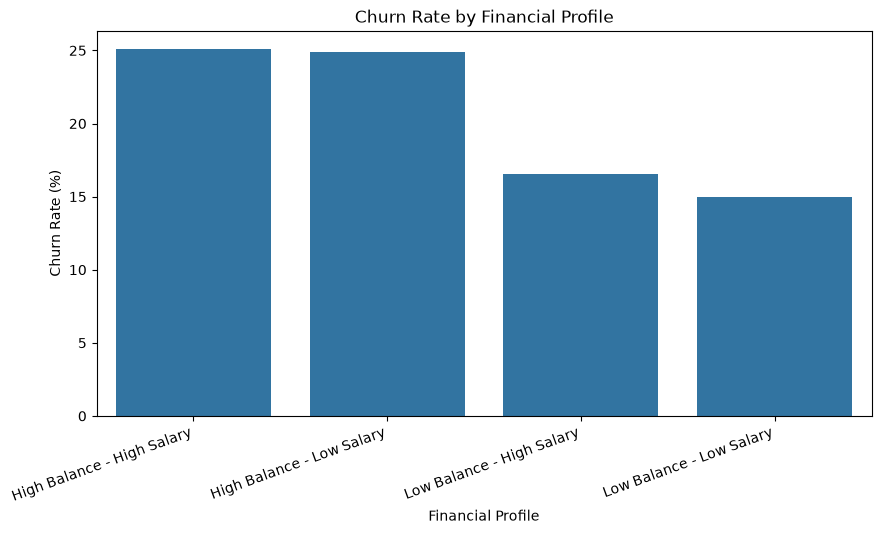

In [60]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=financial_profile_summary.reset_index(),
    x="Financial_Profile",
    y="Churn_Rate"
)

plt.title("Churn Rate by Financial Profile")
plt.xlabel("Financial Profile")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

plt.show()

### 8.5 Identification of Potentially At-Risk High-Balance Customers

Inactive customers with balances above the dataset median are examined to identify customers who may require retention attention.

Among these customers, those who have not yet exited are considered potentially at risk. This provides a focused group for targeted customer engagement strategies.

In [61]:
high_balance_inactive = df[
    (df["Balance"] > median_balance) &
    (df["IsActiveMember"] == 0)
]

at_risk_customers = high_balance_inactive[
    high_balance_inactive["Exited"] == 0
]

print("Inactive High-Balance Customers:", len(high_balance_inactive))
print("Already Exited Customers:", high_balance_inactive["Exited"].sum())
print("Potentially At-Risk Customers:", len(at_risk_customers))

Inactive High-Balance Customers: 2456
Already Exited Customers: 794
Potentially At-Risk Customers: 1662


In [62]:
at_risk_summary = at_risk_customers.agg(
    Total_Customers=("CustomerId", "count"),
    Average_Balance=("Balance", "mean"),
    Average_Salary=("EstimatedSalary", "mean"),
    Average_Age=("Age", "mean")
)

at_risk_summary

,CustomerId,Balance,EstimatedSalary,Age
Total_Customers,1662.0,NaN,NaN,NaN
Average_Balance,NaN,131360.359621,NaN,NaN
Average_Salary,NaN,NaN,101354.855391,NaN
Average_Age,NaN,NaN,NaN,35.634777


**At-Risk Customer Profile**

The analysis identified 1,662 retained customers who have above-median account balances but are currently inactive.

| Metric | Value |
|---|---:|
| Potentially At-Risk Customers | 1,662 |
| Average Balance | 131,360.36 |
| Average Estimated Salary | 101,354.86 |
| Average Age | 35.63 years |

**Key Observation:** These customers hold substantial account balances despite being inactive. They represent an important group for targeted re-engagement campaigns. Their inactivity does not guarantee future churn, so they should be treated as a monitoring priority rather than confirmed churn risks.

### 8.6 Document Your Findings

The financial and engagement analysis examined account balance, estimated salary, customer activity, and churn to identify patterns associated with customer retention.

**Financial and Engagement Summary**

| Metric | Result | Interpretation |
|---|---:|---|
| Median Account Balance | 97,198.54 | Used to identify high-balance customers. |
| Inactive High-Balance Customers | 2,456 | Customers with above-median balance who are inactive. |
| Potentially At-Risk Customers | 1,662 | Inactive high-balance customers who have not exited. |
| Average Balance of Retained Customers | 72,745.30 | Lower than the average balance of exited customers. |
| Average Balance of Exited Customers | 91,108.54 | Exited customers had higher average balances. |
| Salary-Balance Correlation | 0.0128 | Almost no linear relationship between salary and balance. |

**Key Observations**

- Inactive high-balance customers account for 2,456 customers. Of these, 1,662 were retained and 794 had already exited.
- Approximately 67.67% of inactive high-balance customers were retained, while 32.33% had exited.
- Exited customers had a higher average account balance (91,108.54) than retained customers (72,745.30).
- The average account balance of inactive customers (77,134.38) was slightly higher than that of active customers (75,875.42).
- The average estimated salary of exited customers (101,465.68) was slightly higher than that of retained customers (99,738.39).
- The correlation between estimated salary and account balance was approximately 0.013, indicating almost no linear relationship between these two variables.

**Financial Profile Analysis**

| Financial Profile | Churn Rate | Interpretation |
|---|---:|---|
| High Balance - High Salary | 25.08% | Highest churn rate among the four financial profiles. |
| High Balance - Low Salary | 24.88% | Also shows relatively high customer churn. |
| Low Balance - High Salary | 16.55% | Lower churn than the high-balance groups. |
| Low Balance - Low Salary | 14.98% | Lowest churn rate among the four profiles. |

**Business Implications**

- Prioritize re-engagement campaigns for inactive high-balance customers who have not yet exited.
- Investigate why customers with higher account balances show greater churn in this dataset.
- Use both financial characteristics and engagement status when identifying potentially at-risk customers.
- Avoid using estimated salary alone to predict account balance or customer retention.

**Conclusion**

The analysis identifies inactive high-balance customers as an important group for retention monitoring. Financial profiles also show differences in churn rates, with both high-balance groups recording higher churn than the low-balance groups. However, account balance and estimated salary alone cannot fully explain customer churn. Combining financial characteristics with customer engagement provides a more useful basis for identifying potential retention opportunities.

## 9. Retention Strength Analysis

This section evaluates customer retention strength using five key performance indicators (KPIs):

1. Engagement Retention Ratio
2. Product Depth Index
3. High-Balance Disengagement Rate
4. Credit Card Stickiness Score
5. Relationship Strength Index

These indicators are calculated using customer engagement, product utilization, financial characteristics, and account relationship data.

The KPI formulas are project-defined operational measures based on the available dataset. They are descriptive indicators and should not be interpreted as predictive churn probabilities.

### 9.1 Engagement Retention Ratio

The Engagement Retention Ratio measures the proportion of active customers who have not exited the bank.

A higher ratio indicates stronger retention among active customers.

In [64]:
# Identify active customers
active_customers = df[df["IsActiveMember"] == 1]

# Identify active customers who have not exited
active_retained = active_customers[
    active_customers["Exited"] == 0
]

# Calculate engagement retention ratio
engagement_retention_ratio = (
    len(active_retained) / len(active_customers)
) * 100

print("Total Active Customers:", len(active_customers))
print("Active Retained Customers:", len(active_retained))
print(
    "Engagement Retention Ratio:",
    round(engagement_retention_ratio, 2), "%"
)

Total Active Customers: 5151
Active Retained Customers: 4416
Engagement Retention Ratio: 85.73 %


### 9.2 Product Depth Index

The Product Depth Index measures the average number of banking products held by retained customers.

It helps assess the depth of customer relationships and provides a comparison between retained and exited customers.

In [65]:
# Calculate average product count by customer status
product_depth_summary = df.groupby("Exited").agg(
    Total_Customers=("CustomerId", "count"),
    Average_Product_Count=("NumOfProducts", "mean"),
    Median_Product_Count=("NumOfProducts", "median")
)

product_depth_summary.index = product_depth_summary.index.map({
    0: "Retained",
    1: "Exited"
})

product_depth_index = product_depth_summary.loc[
    "Retained", "Average_Product_Count"
]

display(product_depth_summary.round(2))

print(
    "Product Depth Index:",
    round(product_depth_index, 2)
)

,Total_Customers,Average_Product_Count,Median_Product_Count
Exited,,,
Retained,7963,1.54,2.0
Exited,2037,1.48,1.0


Product Depth Index: 1.54


### 9.3 High-Balance Disengagement Rate

The High-Balance Disengagement Rate measures the percentage of customers with above-median account balances who are currently inactive.

This indicator helps identify financially significant customer relationships that may require additional engagement.

In [66]:
# Identify all customers with above-median balances
high_balance_customers = df[
    df["Balance"] > median_balance
]

# Identify inactive customers within this group
inactive_high_balance = high_balance_customers[
    high_balance_customers["IsActiveMember"] == 0
]

# Calculate disengagement rate
high_balance_disengagement_rate = (
    len(inactive_high_balance) /
    len(high_balance_customers)
) * 100

print(
    "Total High-Balance Customers:",
    len(high_balance_customers)
)

print(
    "Inactive High-Balance Customers:",
    len(inactive_high_balance)
)

print(
    "High-Balance Disengagement Rate:",
    round(high_balance_disengagement_rate, 2), "%"
)

Total High-Balance Customers: 5000
Inactive High-Balance Customers: 2456
High-Balance Disengagement Rate: 49.12 %


### 9.4 Credit Card Stickiness Score

The Credit Card Stickiness Score measures the percentage of credit card holders who have remained with the bank.

It helps evaluate retention among customers who use the bank's credit card service. This measure indicates an association and does not establish that credit card ownership causes customer retention.

In [68]:
# Identify credit card holders
credit_card_customers = df[
    df["HasCrCard"] == 1
]

# Identify retained credit card holders
retained_cardholders = credit_card_customers[
    credit_card_customers["Exited"] == 0
]

# Calculate Credit Card Stickiness Score
credit_card_stickiness_score = (
    len(retained_cardholders) /
    len(credit_card_customers)
) * 100

print("Total Credit Card Holders:", len(credit_card_customers))
print("Retained Credit Card Holders:", len(retained_cardholders))
print(
    "Credit Card Stickiness Score:",
    round(credit_card_stickiness_score, 2), "%"
)

Total Credit Card Holders: 7055
Retained Credit Card Holders: 5631
Credit Card Stickiness Score: 79.82 %


### 9.5 Relationship Strength Index

The Relationship Strength Index is a project-defined composite indicator that combines customer activity, credit card ownership, product depth, and account tenure.

Each component contributes equally to the final score, which ranges from 0 to 100. A higher score represents stronger values across the selected relationship characteristics.

The index is descriptive and is not a predictive churn model.

In [69]:
# Normalize relationship characteristics
activity_score = df["IsActiveMember"]

card_score = df["HasCrCard"]

product_score = df["NumOfProducts"].clip(upper=2) / 2

tenure_score = df["Tenure"] / 10

# Calculate Relationship Strength Index
df["Relationship_Strength_Index"] = (
    activity_score +
    card_score +
    product_score +
    tenure_score
) / 4 * 100

# Compare scores by customer status
relationship_strength_summary = df.groupby("Exited").agg(
    Total_Customers=("CustomerId", "count"),
    Average_Relationship_Strength=(
        "Relationship_Strength_Index", "mean"
    ),
    Median_Relationship_Strength=(
        "Relationship_Strength_Index", "median"
    )
)

relationship_strength_summary.index = (
    relationship_strength_summary.index.map({
        0: "Retained",
        1: "Exited"
    })
)

display(relationship_strength_summary.round(2))

,Total_Customers,Average_Relationship_Strength,Median_Relationship_Strength
Exited,,,
Retained,7963,63.36,65.0
Exited,2037,55.18,55.0


### 9.6 Consolidated Retention KPI Summary

The five retention indicators are combined into a single summary table to provide an overall view of customer retention strength.

The table presents the calculated values alongside their respective measurement units.

In [70]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Engagement Retention Ratio",
        "Product Depth Index",
        "High-Balance Disengagement Rate",
        "Credit Card Stickiness Score",
        "Relationship Strength Index"
    ],
    "Value": [
        round(engagement_retention_ratio, 2),
        round(product_depth_index, 2),
        round(high_balance_disengagement_rate, 2),
        round(credit_card_stickiness_score, 2),
        round(df["Relationship_Strength_Index"].mean(), 2)
    ],
    "Unit": [
        "%",
        "Products per retained customer",
        "%",
        "%",
        "Score out of 100"
    ]
})

display(kpi_summary)

,KPI,Value,Unit
0,Engagement Retention Ratio,85.73,%
1,Product Depth Index,1.54,Products per retained customer
2,High-Balance Disengagement Rate,49.12,%
3,Credit Card Stickiness Score,79.82,%
4,Relationship Strength Index,61.69,Score out of 100


### 9.7 KPI Validation

Validation checks are performed to verify customer counts, score ranges, and KPI calculation consistency.

These checks help ensure that the retention indicators are calculated correctly.

In [71]:
validation_results = {
    "Total Customer Count": len(df),
    "Active Customer Count": len(active_customers),
    "High-Balance Customer Count": len(high_balance_customers),
    "Credit Card Holder Count": len(credit_card_customers),
    "Relationship Index Minimum": df[
        "Relationship_Strength_Index"
    ].min(),
    "Relationship Index Maximum": df[
        "Relationship_Strength_Index"
    ].max()
}

for check, result in validation_results.items():
    print(f"{check}: {result}")

# Check that the Relationship Strength Index is within range
assert df["Relationship_Strength_Index"].between(0, 100).all()

# Check that all percentage KPIs are within valid limits
assert 0 <= engagement_retention_ratio <= 100
assert 0 <= high_balance_disengagement_rate <= 100
assert 0 <= credit_card_stickiness_score <= 100

print("\nAll KPI validation checks passed.")

Total Customer Count: 10000
Active Customer Count: 5151
High-Balance Customer Count: 5000
Credit Card Holder Count: 7055
Relationship Index Minimum: 12.5
Relationship Index Maximum: 100.0

All KPI validation checks passed.


### 9.8 Document Your Findings

The retention strength analysis evaluated five key performance indicators to understand customer engagement, product utilization, and relationship strength.

**Retention KPI Summary**

| KPI | Result |
|---|---:|
| Engagement Retention Ratio | 85.73% |
| Product Depth Index | 1.54 |
| High-Balance Disengagement Rate | 49.12% |
| Credit Card Stickiness Score | 79.82% |
| Relationship Strength Index | 61.69/100 |

**Key Observations**

- **Customer Engagement:** The Engagement Retention Ratio is 85.73%, indicating that most active customers have remained with the bank.
- **Product Utilization:** Retained customers hold an average of 1.54 products, compared with 1.48 among exited customers. The difference is relatively small.
- **High-Balance Disengagement:** Approximately 49.12% of above-median-balance customers are inactive, highlighting a significant customer engagement opportunity.
- **Credit Card Retention:** The Credit Card Stickiness Score is 79.82%, showing that most credit card holders have remained with the bank.
- **Relationship Strength:** Retained customers have an average Relationship Strength Index of 63.36, compared with 55.18 for exited customers. This suggests that the selected relationship characteristics are associated with stronger retention.

**Business Implications**

1. Prioritize re-engagement campaigns for inactive, high-balance customers.
2. Encourage meaningful product adoption rather than simply increasing the number of products held.
3. Monitor credit card holders who show signs of disengagement.
4. Strengthen customer relationships through consistent engagement and improved service.

**Conclusion**

The analysis indicates that customer activity, product utilization, credit card ownership, and tenure provide useful insights into retention strength. Retained customers generally show higher relationship strength scores than exited customers. These indicators can support targeted retention strategies, but they should not be interpreted as proof of causation or as individual churn predictions.

## 10. Customer Retention Stability

This section examines customer retention patterns across different tenure groups, activity levels, and credit card ownership categories.

The analysis identifies customer groups with relatively high or low churn rates and evaluates the consistency of retention across these characteristics.

The findings will help identify customer groups that may require additional retention strategies.

### 10.1 Retention Across Customer Tenure

Customer tenure represents the number of years a customer has maintained a relationship with the bank.

This analysis compares customer counts and churn rates across tenure groups to identify differences in retention patterns.

In [72]:
# Calculate customer retention by tenure
tenure_retention = df.groupby("Tenure").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum")
)

tenure_retention["Retained_Customers"] = (
    tenure_retention["Total_Customers"] -
    tenure_retention["Exited_Customers"]
)

tenure_retention["Churn_Rate"] = (
    tenure_retention["Exited_Customers"] /
    tenure_retention["Total_Customers"]
) * 100

tenure_retention["Retention_Rate"] = (
    tenure_retention["Retained_Customers"] /
    tenure_retention["Total_Customers"]
) * 100

display(tenure_retention.round(2))

,Total_Customers,Exited_Customers,Retained_Customers,Churn_Rate,Retention_Rate
Tenure,,,,,
0,413,95,318,23.00,77.00
1,1035,232,803,22.42,77.58
2,1048,201,847,19.18,80.82
3,1009,213,796,21.11,78.89
4,989,203,786,20.53,79.47
5,1012,209,803,20.65,79.35
6,967,196,771,20.27,79.73
7,1028,177,851,17.22,82.78
8,1025,197,828,19.22,80.78


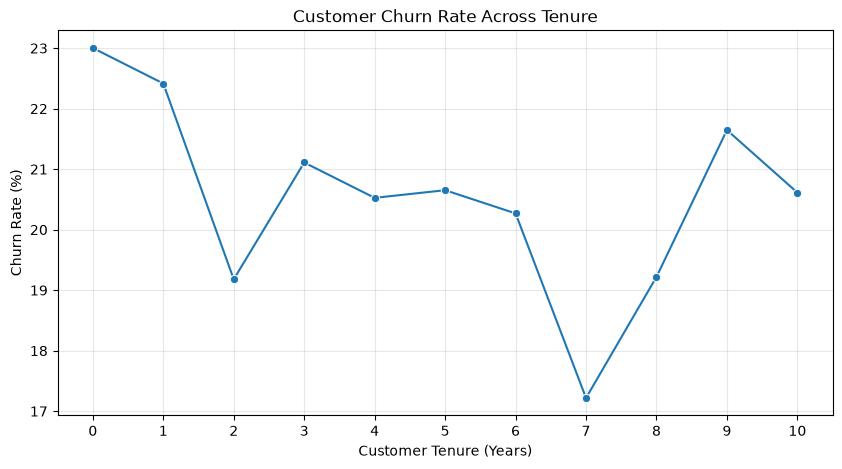

In [73]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=tenure_retention,
    x=tenure_retention.index,
    y="Churn_Rate",
    marker="o"
)

plt.title("Customer Churn Rate Across Tenure")
plt.xlabel("Customer Tenure (Years)")
plt.ylabel("Churn Rate (%)")
plt.xticks(range(0, 11))
plt.grid(True, alpha=0.3)
plt.show()

### 10.2 Retention by Customer Activity

Customer activity is an important indicator of engagement with the bank.

This analysis compares retention and churn rates between active and inactive customers to understand how account activity relates to customer retention.

In [74]:
# Calculate retention by activity status
activity_retention = df.groupby("IsActiveMember").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum")
)

activity_retention["Retained_Customers"] = (
    activity_retention["Total_Customers"] -
    activity_retention["Exited_Customers"]
)

activity_retention["Churn_Rate"] = (
    activity_retention["Exited_Customers"] /
    activity_retention["Total_Customers"]
) * 100

activity_retention["Retention_Rate"] = (
    activity_retention["Retained_Customers"] /
    activity_retention["Total_Customers"]
) * 100

activity_retention.index = activity_retention.index.map({
    0: "Inactive",
    1: "Active"
})

display(activity_retention.round(2))

,Total_Customers,Exited_Customers,Retained_Customers,Churn_Rate,Retention_Rate
IsActiveMember,,,,,
Inactive,4849,1302,3547,26.85,73.15
Active,5151,735,4416,14.27,85.73


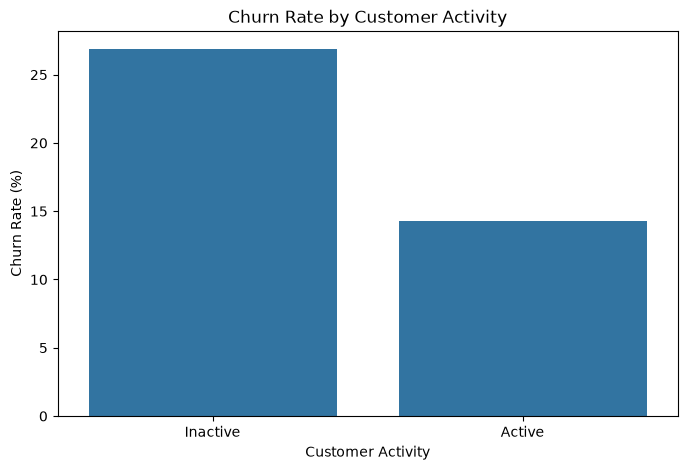

In [75]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=activity_retention.reset_index(),
    x="IsActiveMember",
    y="Churn_Rate"
)

plt.title("Churn Rate by Customer Activity")
plt.xlabel("Customer Activity")
plt.ylabel("Churn Rate (%)")
plt.show()

### 10.3 Retention by Credit Card Ownership

Credit card ownership represents one aspect of a customer's relationship with the bank.

This analysis compares retention rates between credit card holders and non-cardholders to identify differences in customer retention.

In [76]:
# Calculate retention by credit card ownership
card_retention = df.groupby("HasCrCard").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum")
)

card_retention["Retained_Customers"] = (
    card_retention["Total_Customers"] -
    card_retention["Exited_Customers"]
)

card_retention["Churn_Rate"] = (
    card_retention["Exited_Customers"] /
    card_retention["Total_Customers"]
) * 100

card_retention["Retention_Rate"] = (
    card_retention["Retained_Customers"] /
    card_retention["Total_Customers"]
) * 100

card_retention.index = card_retention.index.map({
    0: "No Credit Card",
    1: "Credit Card Holder"
})

display(card_retention.round(2))

,Total_Customers,Exited_Customers,Retained_Customers,Churn_Rate,Retention_Rate
HasCrCard,,,,,
No Credit Card,2945,613,2332,20.81,79.19
Credit Card Holder,7055,1424,5631,20.18,79.82


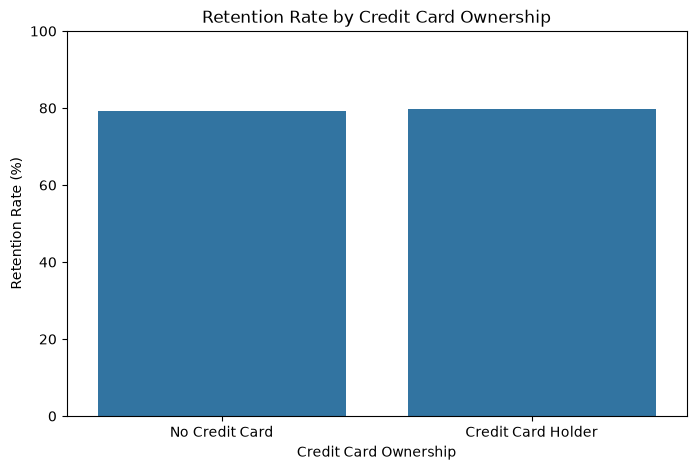

In [77]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=card_retention.reset_index(),
    x="HasCrCard",
    y="Retention_Rate"
)

plt.title("Retention Rate by Credit Card Ownership")
plt.xlabel("Credit Card Ownership")
plt.ylabel("Retention Rate (%)")
plt.ylim(0, 100)
plt.show()

### 10.4 Retention Across Tenure and Activity Groups

This analysis combines customer tenure and activity status to examine how engagement relates to churn across different relationship durations.

It helps identify whether inactive customers consistently experience higher churn across tenure groups or whether certain tenure groups show different patterns.

In [78]:
# Calculate churn by tenure and activity
tenure_activity = df.pivot_table(
    index="Tenure",
    columns="IsActiveMember",
    values="Exited",
    aggfunc="mean"
) * 100

tenure_activity.columns = ["Inactive", "Active"]

display(tenure_activity.round(2))

,Inactive,Active
Tenure,,
0,27.84,18.72
1,31.12,15.29
2,26.43,12.86
3,26.60,16.03
4,27.40,13.80
5,26.68,14.62
6,26.71,14.23
7,22.52,12.34
8,24.70,13.87


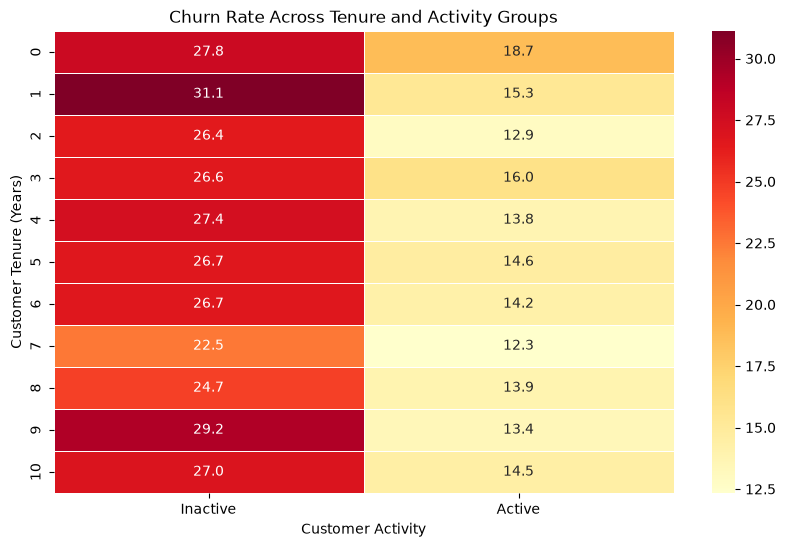

In [79]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    tenure_activity,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Churn Rate Across Tenure and Activity Groups")
plt.xlabel("Customer Activity")
plt.ylabel("Customer Tenure (Years)")
plt.show()

### 10.5 Retention Stability Summary

The retention stability analysis compares customer retention across tenure, activity status, and credit card ownership.

The results help identify customer groups with different retention patterns and highlight characteristics that may require additional monitoring.

In [80]:
# Identify highest and lowest tenure churn rates
highest_tenure_churn = tenure_retention["Churn_Rate"].idxmax()
lowest_tenure_churn = tenure_retention["Churn_Rate"].idxmin()

# Identify activity group churn rates
inactive_churn = activity_retention.loc[
    "Inactive", "Churn_Rate"
]

active_churn = activity_retention.loc[
    "Active", "Churn_Rate"
]

# Identify credit card group retention rates
cardholder_retention = card_retention.loc[
    "Credit Card Holder", "Retention_Rate"
]

non_cardholder_retention = card_retention.loc[
    "No Credit Card", "Retention_Rate"
]

print("Highest Churn Tenure:", highest_tenure_churn)
print(
    "Highest Churn Rate:",
    round(tenure_retention.loc[highest_tenure_churn, "Churn_Rate"], 2),
    "%"
)

print("\nLowest Churn Tenure:", lowest_tenure_churn)
print(
    "Lowest Churn Rate:",
    round(tenure_retention.loc[lowest_tenure_churn, "Churn_Rate"], 2),
    "%"
)

print("\nInactive Customer Churn:", round(inactive_churn, 2), "%")
print("Active Customer Churn:", round(active_churn, 2), "%")

print(
    "\nCredit Card Holder Retention:",
    round(cardholder_retention, 2), "%"
)

print(
    "Non-Cardholder Retention:",
    round(non_cardholder_retention, 2), "%"
)

Highest Churn Tenure: 0
Highest Churn Rate: 23.0 %

Lowest Churn Tenure: 7
Lowest Churn Rate: 17.22 %

Inactive Customer Churn: 26.85 %
Active Customer Churn: 14.27 %

Credit Card Holder Retention: 79.82 %
Non-Cardholder Retention: 79.19 %


### 10.6 Retention Analysis Validation

Validation checks ensure that customer counts are consistent across tenure, activity, and credit card ownership groups.

The churn rates are also checked to confirm that they remain within the valid percentage range.

In [81]:
# Validate customer counts
assert tenure_retention["Total_Customers"].sum() == len(df)
assert activity_retention["Total_Customers"].sum() == len(df)
assert card_retention["Total_Customers"].sum() == len(df)

# Validate exited customer counts
assert tenure_retention["Exited_Customers"].sum() == df["Exited"].sum()
assert activity_retention["Exited_Customers"].sum() == df["Exited"].sum()
assert card_retention["Exited_Customers"].sum() == df["Exited"].sum()

# Validate churn rate ranges
assert tenure_retention["Churn_Rate"].between(0, 100).all()
assert activity_retention["Churn_Rate"].between(0, 100).all()
assert card_retention["Churn_Rate"].between(0, 100).all()

print("All retention validation checks passed.")

All retention validation checks passed.


### 10.7 Document Your Findings

The retention stability analysis examined customer churn across tenure groups, activity status, and credit card ownership.

**1. Retention Across Customer Tenure**

- Customers with 0 years of tenure recorded the highest churn rate of 23.00%.
- Customers with 7 years of tenure recorded the lowest churn rate of 17.22%.
- Churn rates across tenure groups generally remained between 17% and 23%.

This indicates that customer tenure alone does not consistently determine retention.

**2. Retention by Customer Activity**

- Inactive customers recorded a churn rate of 26.85%.
- Active customers recorded a churn rate of 14.27%.
- Active customers had a retention rate of 85.73%, compared with 73.15% for inactive customers.

Customer activity shows a substantial association with retention and should be considered an important engagement indicator.

**3. Retention by Credit Card Ownership**

- Credit card holders recorded a retention rate of 79.82%.
- Customers without credit cards recorded a retention rate of 79.19%.
- The difference was only 0.63 percentage points.

This suggests that credit card ownership alone provides limited differentiation in customer retention.

**4. Retention Across Tenure and Activity Groups**

The tenure and activity analysis showed that inactive customers consistently had higher churn rates than active customers across all tenure groups.

This indicates that customer engagement is an important retention factor regardless of relationship duration.

**Business Implications**

1. Prioritize re-engagement campaigns for inactive customers.
2. Monitor newly acquired customers during their early relationship period.
3. Strengthen engagement throughout the customer lifecycle rather than relying only on tenure.
4. Use credit card ownership alongside other customer characteristics when developing retention strategies.

**Conclusion**

Customer activity shows a stronger association with retention than tenure or credit card ownership in this dataset. Consistent engagement monitoring and targeted re-engagement strategies may help improve customer retention.

## 11. Customer Risk Prioritization

This section develops a rule-based framework to prioritize customers for retention activities.

Customer groups are classified using account activity, account balance, and product count. Their churn rates are compared to identify groups requiring greater attention.

The analysis distinguishes between customers who have already exited and retained customers who may be at risk of future churn.

The resulting categories are analytical classifications, not predictions generated by a machine learning model.

### 11.1 Definition of Customer Risk Categories

Customers are classified into five mutually exclusive categories using account activity, account balance, and product count.

The categories are based on patterns observed in the earlier analysis. They are intended to prioritize retention monitoring and do not represent individual churn probabilities.

Customers who have already exited are retained in the analysis for group-level churn comparisons but are excluded from the actionable retention target list.

In [82]:
# Define mutually exclusive risk categories
conditions = [
    (df["IsActiveMember"] == 0) &
    (df["Balance"] > median_balance),

    (df["IsActiveMember"] == 0) &
    (df["Balance"] <= median_balance),

    (df["IsActiveMember"] == 1) &
    (df["NumOfProducts"] == 1),

    (df["IsActiveMember"] == 1) &
    (df["NumOfProducts"] == 2),

    (df["IsActiveMember"] == 1) &
    (df["NumOfProducts"].isin([3, 4]))
]

risk_categories = [
    "High Priority",
    "Elevated Priority",
    "Moderate Priority",
    "Lower Priority",
    "Special Monitoring"
]

df["Risk_Category"] = np.select(
    conditions,
    risk_categories,
    default="Unclassified"
)

print(df["Risk_Category"].value_counts())

Risk_Category
Moderate Priority     2563
High Priority         2456
Lower Priority        2446
Elevated Priority     2393
Special Monitoring     142
Name: count, dtype: int64


### 11.2 Customer Risk Distribution

This analysis calculates the number and percentage of customers assigned to each risk category.

It provides an overview of the customer population requiring different levels of retention monitoring.

In [83]:
# Summarize customer risk categories
risk_distribution = df.groupby("Risk_Category").agg(
    Total_Customers=("CustomerId", "count")
)

risk_distribution["Customer_Percentage"] = (
    risk_distribution["Total_Customers"] /
    len(df)
) * 100

display(risk_distribution.round(2))

,Total_Customers,Customer_Percentage
Risk_Category,,
Elevated Priority,2393,23.93
High Priority,2456,24.56
Lower Priority,2446,24.46
Moderate Priority,2563,25.63
Special Monitoring,142,1.42


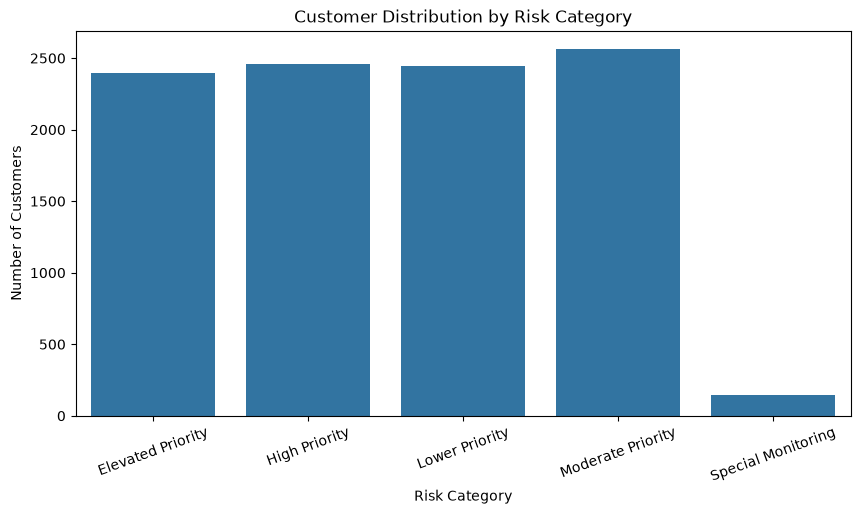

In [84]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=risk_distribution.reset_index(),
    x="Risk_Category",
    y="Total_Customers"
)

plt.title("Customer Distribution by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.show()

### 11.3 Churn Rate Across Risk Categories

This analysis compares historical churn rates across the defined customer risk categories.

It helps evaluate whether the rule-based classification reflects the differences in churn patterns observed in the dataset.

In [85]:
# Calculate churn statistics by risk category
risk_churn_summary = df.groupby("Risk_Category").agg(
    Total_Customers=("CustomerId", "count"),
    Exited_Customers=("Exited", "sum")
)

risk_churn_summary["Retained_Customers"] = (
    risk_churn_summary["Total_Customers"] -
    risk_churn_summary["Exited_Customers"]
)

risk_churn_summary["Churn_Rate"] = (
    risk_churn_summary["Exited_Customers"] /
    risk_churn_summary["Total_Customers"]
) * 100

risk_churn_summary["Retention_Rate"] = (
    risk_churn_summary["Retained_Customers"] /
    risk_churn_summary["Total_Customers"]
) * 100

display(risk_churn_summary.round(2))

,Total_Customers,Exited_Customers,Retained_Customers,Churn_Rate,Retention_Rate
Risk_Category,,,,,
Elevated Priority,2393,508,1885,21.23,78.77
High Priority,2456,794,1662,32.33,67.67
Lower Priority,2446,136,2310,5.56,94.44
Moderate Priority,2563,485,2078,18.92,81.08
Special Monitoring,142,114,28,80.28,19.72


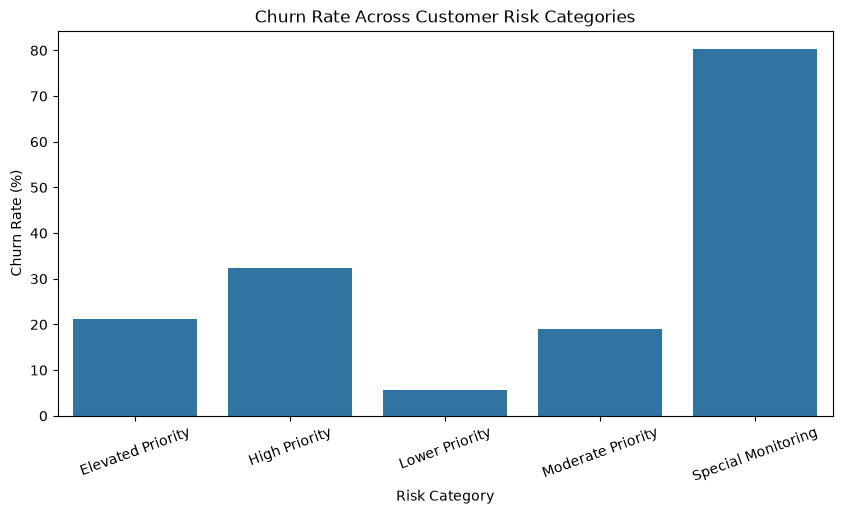

In [86]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=risk_churn_summary.reset_index(),
    x="Risk_Category",
    y="Churn_Rate"
)

plt.title("Churn Rate Across Customer Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.show()

### 11.4 Identification of Potentially At-Risk Customers

Customers classified as High Priority are examined separately to identify those who have not yet exited the bank.

This group consists of inactive customers with above-median account balances. These customers represent an important opportunity for targeted re-engagement campaigns.

In [87]:
# Identify retained customers in the High Priority category
high_priority_retained = df[
    (df["Risk_Category"] == "High Priority") &
    (df["Exited"] == 0)
].copy()

# Display selected customer information
at_risk_customers = high_priority_retained[
    [
        "CustomerId",
        "Age",
        "Tenure",
        "Balance",
        "EstimatedSalary",
        "NumOfProducts",
        "IsActiveMember",
        "Risk_Category"
    ]
]

print(
    "Potentially At-Risk High Priority Customers:",
    len(at_risk_customers)
)

display(at_risk_customers.head())

Potentially At-Risk High Priority Customers: 1662


,CustomerId,Age,Tenure,Balance,EstimatedSalary,NumOfProducts,IsActiveMember,Risk_Category
10,15767821,31,6,102016.72,80181.12,2,0,High Priority
32,15750181,41,9,110112.54,81898.81,2,0,High Priority
49,15771873,37,2,103769.22,194099.12,2,0,High Priority
50,15616550,44,10,116363.37,198059.16,2,0,High Priority
51,15768193,36,5,146050.97,86424.57,2,0,High Priority


In [88]:
# Profile of retained high-priority customers
high_priority_profile = high_priority_retained.agg({
    "CustomerId": "count",
    "Balance": "mean",
    "EstimatedSalary": "mean",
    "Age": "mean",
    "Tenure": "mean"
})

display(high_priority_profile.round(2))

CustomerId           1662.00
Balance            131360.36
EstimatedSalary    101354.86
Age                    35.63
Tenure                  5.15
dtype: float64

### 11.5 Risk Category Comparison

This analysis compares the financial and relationship characteristics of customers across risk categories.

The comparison helps identify differences in customer profiles and provides additional context for designing retention strategies.

In [89]:
# Compare customer characteristics by risk category
risk_profile = df.groupby("Risk_Category").agg(
    Total_Customers=("CustomerId", "count"),
    Average_Age=("Age", "mean"),
    Average_Tenure=("Tenure", "mean"),
    Average_Balance=("Balance", "mean"),
    Average_Product_Count=("NumOfProducts", "mean")
)

display(risk_profile.round(2))

,Total_Customers,Average_Age,Average_Tenure,Average_Balance,Average_Product_Count
Risk_Category,,,,,
Elevated Priority,2393,37.48,5.07,21685.34,1.67
High Priority,2456,38.50,5.12,131161.07,1.38
Lower Priority,2446,39.09,4.96,51852.94,2.00
Moderate Priority,2563,40.25,4.89,98902.02,1.00
Special Monitoring,142,43.65,5.36,74057.29,3.20


### 11.6 Risk Prioritization Summary

The risk prioritization summary combines customer distribution, historical churn rates, and the number of retained customers in each category.

It provides a consolidated view of customer groups requiring different levels of retention attention.

In [90]:
# Combine risk distribution and churn information
risk_priority_summary = risk_churn_summary.copy()

risk_priority_summary["Customer_Percentage"] = (
    risk_priority_summary["Total_Customers"] /
    len(df)
) * 100

# Count retained customers available for retention action
retained_priority_counts = (
    df[df["Exited"] == 0]
    .groupby("Risk_Category")
    .size()
    .rename("Retained_Customers_For_Action")
)

risk_priority_summary = risk_priority_summary.join(
    retained_priority_counts
)

risk_priority_summary["Retained_Customers_For_Action"] = (
    risk_priority_summary["Retained_Customers_For_Action"]
    .fillna(0)
    .astype(int)
)

display(risk_priority_summary.round(2))

,Total_Customers,Exited_Customers,Retained_Customers,Churn_Rate,Retention_Rate,Customer_Percentage,Retained_Customers_For_Action
Risk_Category,,,,,,,
Elevated Priority,2393,508,1885,21.23,78.77,23.93,1885
High Priority,2456,794,1662,32.33,67.67,24.56,1662
Lower Priority,2446,136,2310,5.56,94.44,24.46,2310
Moderate Priority,2563,485,2078,18.92,81.08,25.63,2078
Special Monitoring,142,114,28,80.28,19.72,1.42,28


### 11.7 Risk Analysis Validation

Validation checks are performed to confirm that all customers have been assigned to a risk category and that customer counts and churn totals remain consistent with the original dataset.

The retained high-priority customer count is also compared with the result obtained in the financial analysis.

In [91]:
# Validate risk classification
assert (df["Risk_Category"] != "Unclassified").all()

# Validate total customer count
assert risk_churn_summary["Total_Customers"].sum() == len(df)

# Validate exited customer count
assert risk_churn_summary["Exited_Customers"].sum() == df["Exited"].sum()

# Validate retained customer count
assert risk_churn_summary["Retained_Customers"].sum() == (
    (df["Exited"] == 0).sum()
)

# Validate potentially at-risk customers
assert len(high_priority_retained) == 1662

# Confirm that no exited customers are included in the action list
assert (high_priority_retained["Exited"] == 0).all()

print("Unclassified Customers:", 
      (df["Risk_Category"] == "Unclassified").sum())

print("Total Customers:", len(df))

print("Total Exited Customers:", df["Exited"].sum())

print("Potentially At-Risk Customers:", len(high_priority_retained))

print("\nAll risk analysis validation checks passed.")

Unclassified Customers: 0
Total Customers: 10000
Total Exited Customers: 2037
Potentially At-Risk Customers: 1662

All risk analysis validation checks passed.


### 11.8 Document Your Findings

The customer risk prioritization analysis classified 10,000 customers into five mutually exclusive categories using account activity, account balance, and product count.

**1. Customer Risk Distribution**

| Risk Category | Customers | Percentage |
|---|---:|---:|
| High Priority | 2,456 | 24.56% |
| Elevated Priority | 2,393 | 23.93% |
| Moderate Priority | 2,563 | 25.63% |
| Lower Priority | 2,446 | 24.46% |
| Special Monitoring | 142 | 1.42% |

**2. Churn Rate Across Risk Categories**

| Risk Category | Churn Rate |
|---|---:|
| High Priority | 32.33% |
| Elevated Priority | 21.23% |
| Moderate Priority | 18.92% |
| Lower Priority | 5.56% |
| Special Monitoring | 80.28% |

Special Monitoring customers recorded the highest churn rate. However, this category contains only 142 customers, so the result should be interpreted cautiously.

**3. Potentially At-Risk High-Priority Customers**

The analysis identified 1,662 retained customers who are inactive and have above-median account balances.

| Metric | Value |
|---|---:|
| Potentially At-Risk Customers | 1,662 |
| Average Balance | 131,360.36 |
| Average Estimated Salary | 101,354.86 |
| Average Age | 35.63 years |
| Average Tenure | 5.15 years |

These customers represent an important opportunity for targeted re-engagement campaigns because they have substantial account balances but are currently inactive.

**4. Customer Profile Comparison**

- High Priority customers have an average balance of approximately 131,161.
- Elevated Priority customers have an average balance of approximately 21,685.
- Lower Priority customers have the lowest observed churn rate at 5.56%.
- Special Monitoring customers have an average product count of 3.20 and an unusually high churn rate of 80.28%.

**5. Business Recommendations**

1. Prioritize re-engagement campaigns for retained High Priority customers.
2. Investigate the reasons behind the unusually high churn among Special Monitoring customers.
3. Monitor Elevated Priority customers to identify signs of further disengagement.
4. Maintain engagement with Lower Priority customers through regular service and relationship-building activities.
5. Design retention strategies according to customer activity, financial characteristics, and product utilization.

**Conclusion**

The analysis identifies different customer groups requiring different retention approaches. High Priority customers represent the largest actionable re-engagement opportunity, while Special Monitoring customers require investigation because of their unusually high historical churn rate. The rule-based classification provides a structured approach to retention prioritization but does not predict individual customer churn.

## 12. Retention Strategy & Business Recommendations

This section translates the customer engagement, product utilization, financial, and risk-prioritization findings into actionable retention strategies. The recommendations focus on identifying customers who may require attention and improving customer relationships.

### 12.1 Targeted Retention Strategy

The following strategies are based on the risk categories developed in Section 11. Retained customers are considered potential targets for retention activities, while historical churn rates help identify groups that require further investigation.

#### Risk-Based Action Plan

| Risk Category | Retained Customers | Historical Churn Rate | Recommended Strategy | Priority |
|---|---:|---:|---|---|
| High Priority | 1,662 | 32.33% | Personalized retention outreach and investigation of inactivity. | Highest |
| Special Monitoring | 28 | 80.28% | Individual customer review and investigation of product usage. | High |
| Elevated Priority | 1,885 | 21.23% | Re-engagement communication and activity monitoring. | Medium |
| Moderate Priority | 2,078 | 18.92% | Assess customer needs and suitable product opportunities. | Medium |
| Lower Priority | 2,310 | 5.56% | Maintain service quality and monitor engagement. | Maintenance |

**Key Observations:**

- High Priority customers represent the largest immediate outreach opportunity, with 1,662 retained customers.
- Special Monitoring has the highest historical churn rate, but contains only 142 customers, of whom 28 are retained.
- Lower Priority customers have the lowest historical churn rate at 5.56%.

*Note: Historical churn rates describe past customer outcomes and should not be interpreted as predictions of future churn.*

In [92]:
risk_action_summary = (
    df.groupby("Risk_Category")
    .agg(
        Total_Customers=("CustomerId", "count"),
        Exited_Customers=("Exited", "sum")
    )
)

risk_action_summary["Retained_Customers"] = (
    risk_action_summary["Total_Customers"]
    - risk_action_summary["Exited_Customers"]
)

risk_action_summary["Historical_Churn_Rate"] = (
    risk_action_summary["Exited_Customers"]
    / risk_action_summary["Total_Customers"] * 100
)

risk_action_summary["Retention_Action"] = {
    "High Priority": "Personalized retention outreach",
    "Special Monitoring": "Individual review and investigation",
    "Elevated Priority": "Re-engagement communication",
    "Moderate Priority": "Product suitability assessment",
    "Lower Priority": "Maintain service and monitor"
}

risk_action_summary = risk_action_summary.sort_values(
    "Historical_Churn_Rate",
    ascending=False
)

risk_action_summary.round(2)

,Total_Customers,Exited_Customers,Retained_Customers,Historical_Churn_Rate,Retention_Action
Risk_Category,,,,,
Special Monitoring,142,114,28,80.28,Individual review and investigation
High Priority,2456,794,1662,32.33,Personalized retention outreach
Elevated Priority,2393,508,1885,21.23,Re-engagement communication
Moderate Priority,2563,485,2078,18.92,Product suitability assessment
Lower Priority,2446,136,2310,5.56,Maintain service and monitor


### 12.2 Engagement-Based Retention Actions

The analysis found that inactive customers had a churn rate of **26.85%**, compared with **14.27%** for active customers. This indicates that inactivity is an important factor to consider when prioritizing retention activities.

| Customer Group | Observation | Recommended Action |
|---|---|---|
| Inactive Customers | Churn rate of 26.85%. | Identify reasons for reduced engagement and initiate re-engagement activities. |
| Inactive High-Balance Customers | 1,662 retained customers in this group. | Prioritize personalized outreach and review their service requirements. |
| Active Customers with One Product | Churn rate of 27.71%. | Assess whether additional products could provide genuine customer value. |
| Active Customers with Two Products | Churn rate of 7.58%. | Maintain engagement and monitor product usage. |
| Customers with Three or Four Products | High historical churn in a small group. | Investigate product suitability and customer experience. |

**Key Observation:** Active customers with two products demonstrate the lowest observed churn rate. However, this does not establish that increasing product count directly reduces churn.

### 12.3 Customer Tenure and Relationship Strategies

The tenure analysis did not show a consistent increase or decrease in churn. Customers with zero years of tenure had a churn rate of 23.00%, while customers with seven years of tenure had the lowest rate at 17.22%.

**Recommended Actions:**

1. **Improve Customer Onboarding:** Establish an early-engagement process to help new customers understand and use banking services.
2. **Monitor Engagement Regularly:** Identify customers whose activity decreases, regardless of their tenure.
3. **Review Customer Experience:** Investigate service-related concerns when customers become inactive.
4. **Avoid Overreliance on Credit Card Ownership:** The retention difference between cardholders and non-cardholders was only 0.63 percentage points.

### 12.4 KPI Monitoring Framework

The following KPIs establish a baseline for monitoring customer engagement and retention performance.

| KPI | Current Baseline | Monitoring Purpose |
|---|---:|---|
| Overall Churn Rate | 20.37% | Measure the proportion of customers exiting. |
| Active Customer Rate | 51.51% | Monitor overall customer engagement. |
| Inactive Customer Churn Rate | 26.85% | Identify disengagement-related churn. |
| High-Balance Disengagement Rate | 49.12% | Monitor inactivity among high-balance customers. |
| Multi-Product Adoption Rate | 49.16% | Measure product utilization depth. |
| Two-Product Customer Churn | 7.58% | Monitor retention among two-product customers. |
| Engagement Retention Ratio | 85.73% | Measure retention among active customers. |

In [93]:
baseline_kpis = pd.DataFrame({
    "KPI": [
        "Overall Churn Rate",
        "Active Customer Rate",
        "Inactive Customer Churn Rate",
        "High-Balance Disengagement Rate",
        "Multi-Product Adoption Rate",
        "Two-Product Customer Churn",
        "Engagement Retention Ratio"
    ],
    "Baseline_Percentage": [
        df["Exited"].mean() * 100,
        df["IsActiveMember"].mean() * 100,
        df.loc[df["IsActiveMember"] == 0, "Exited"].mean() * 100,
        (
            ((df["IsActiveMember"] == 0) &
             (df["Balance"] > median_balance)).sum()
            / (df["Balance"] > median_balance).sum() * 100
        ),
        (df["NumOfProducts"] > 1).mean() * 100,
        df.loc[df["NumOfProducts"] == 2, "Exited"].mean() * 100,
        (
            (df.loc[df["IsActiveMember"] == 1, "Exited"] == 0).sum()
            / (df["IsActiveMember"] == 1).sum() * 100
        )
    ]
})

baseline_kpis["Baseline_Percentage"] = (
    baseline_kpis["Baseline_Percentage"].round(2)
)

baseline_kpis

,KPI,Baseline_Percentage
0,Overall Churn Rate,20.37
1,Active Customer Rate,51.51
2,Inactive Customer Churn Rate,26.85
3,High-Balance Disengagement Rate,49.12
4,Multi-Product Adoption Rate,49.16
5,Two-Product Customer Churn,7.58
6,Engagement Retention Ratio,85.73


**Interpretation:**

These values represent the baseline performance calculated from the available 2025 dataset. Future reporting periods can be compared against these values to evaluate changes in engagement and retention.

- Lower churn and disengagement rates generally indicate improvement.
- Higher active customer rates indicate stronger engagement.
- A higher engagement retention ratio indicates better retention among active customers.

### 12.5 Implementation Roadmap

| Implementation Stage | Recommended Activity | Expected Measurement |
|---|---|---|
| Immediate | Prioritize outreach to retained High Priority customers. | Reduction in high-balance inactive customers. |
| Short Term | Investigate inactivity and customer feedback. | Improvement in active customer rate. |
| Medium Term | Assess product suitability and customer needs. | Improvement in appropriate product adoption. |
| Ongoing | Monitor churn and engagement KPIs. | Reduction in overall and segment-level churn. |

### 12.6 Limitations and Considerations

The recommendations should be interpreted within the limitations of the available dataset.

1. **Cross-Sectional Data:** All customer records belong to 2025. Therefore, long-term retention trends and the impact of retention campaigns cannot be measured.
2. **Association, Not Causation:** Customer inactivity and product count are associated with churn, but the analysis does not prove that they directly cause churn.
3. **Limited Product Information:** The dataset contains product counts but does not provide individual product names or combinations. Therefore, specific product bundles cannot be recommended.
4. **Rule-Based Risk Categories:** The risk categories are based on predefined business rules and are not generated by a trained predictive model.
5. **Small Product Groups:** Customers with three or four products represent a small proportion of the dataset. Their high churn rates require careful interpretation.
6. **Unspecified Currency:** Balance and salary values retain their original dataset units because the currency is not documented.

### 12.7 Key Findings and Business Conclusion

The analysis supports the following conclusions:

- Customer inactivity is an important retention concern. Inactive customers have a substantially higher churn rate than active customers.
- The 1,662 retained inactive high-balance customers represent the primary outreach opportunity.
- Customers with two products demonstrate the lowest observed churn rate.
- Customers with three or four products require further investigation because their historical churn is high despite their small sample size.
- Retention monitoring should combine engagement, product utilization, financial indicators, and customer tenure instead of relying on a single metric.

**Overall Conclusion:**

The bank should prioritize re-engaging inactive high-balance customers, investigate unusual churn patterns among customers with multiple products, and monitor engagement and retention KPIs regularly. These actions provide a data-supported starting point for developing a more effective customer retention strategy.

### 12.8 Final Validation

The following checks verify that the risk summary and KPI calculations are consistent with the original dataset.

In [94]:
strategy_validation = {
    "Risk summary customer count matches dataset":
        risk_action_summary["Total_Customers"].sum() == len(df),

    "Risk summary exited count matches dataset":
        risk_action_summary["Exited_Customers"].sum() == df["Exited"].sum(),

    "Risk summary retained count matches dataset":
        risk_action_summary["Retained_Customers"].sum()
        == (df["Exited"] == 0).sum(),

    "KPI baseline contains no missing values":
        baseline_kpis["Baseline_Percentage"].notna().all(),

    "Risk categories contain no unclassified customers":
        (df["Risk_Category"] != "Unclassified").all()
}

for check, result in strategy_validation.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

Risk summary customer count matches dataset: PASS
Risk summary exited count matches dataset: PASS
Risk summary retained count matches dataset: PASS
KPI baseline contains no missing values: PASS
Risk categories contain no unclassified customers: PASS


## 13. Final Project Summary & Conclusion

This project, **Customer Engagement & Product Utilization Analytics for Retention Strategy**, focused on understanding customer churn patterns, evaluating engagement and product utilization, identifying potentially at-risk customers, and developing data-driven retention recommendations.

The analysis used customer data containing 10,000 records and 14 columns. Python, Pandas, NumPy, Matplotlib, and Seaborn were used for data processing, exploratory analysis, visualization, KPI development, and customer risk prioritization.

### 13.1 Summary of Analytical Work

The project covered the following major analytical activities:

| Section | Analysis Performed | Purpose |
|---|---|---|
| Data Understanding | Dataset structure and variable identification | Understand the available customer information. |
| Data Quality Assessment | Missing values, duplicates, and data types | Assess dataset quality. |
| Data Validation | Range and consistency checks | Verify data reliability. |
| Exploratory Data Analysis | Customer demographics and churn patterns | Identify important customer characteristics. |
| High-Value Disengaged Analysis | Balance and customer activity | Identify potentially valuable disengaged customers. |
| Customer Engagement Classification | Rule-based engagement segments | Understand different customer engagement groups. |
| Product Utilization Analysis | Product count and churn relationship | Evaluate product utilization patterns. |
| Financial and Engagement Analysis | Balance, salary, and activity | Examine financial characteristics associated with churn. |
| Retention Strength Analysis | Five retention KPIs | Measure customer relationship strength. |
| Customer Retention Stability | Tenure, activity, and credit card ownership | Examine retention patterns across customer groups. |
| Customer Risk Prioritization | Rule-based risk categories | Identify customer groups requiring attention. |
| Retention Strategy | Business recommendations and KPI monitoring | Translate findings into actionable retention strategies. |

### 13.2 Key Analytical Findings

The major findings from the analysis are summarized below.

| Metric / Finding | Result | Interpretation |
|---|---:|---|
| Total Customers | 10,000 | Dataset contains 10,000 customer records. |
| Overall Churn Rate | 20.37% | Approximately one-fifth of customers exited. |
| Overall Retention Rate | 79.63% | Most customers remained with the bank. |
| Active Customer Rate | 51.51% | Slightly more than half of customers were active. |
| Inactive Customer Churn | 26.85% | Inactive customers had higher churn. |
| Active Customer Churn | 14.27% | Active customers had lower churn. |
| Single-Product Churn | 27.71% | Single-product customers showed relatively high churn. |
| Two-Product Churn | 7.58% | Two-product customers had the lowest observed churn. |
| High-Balance Disengaged Customers | 2,456 | A substantial group of customers had high balances but were inactive. |
| Retained High-Balance Inactive Customers | 1,662 | These customers represent the primary outreach opportunity. |
| Engagement Retention Ratio | 85.73% | Retention among active customers was relatively high. |
| Credit Card Stickiness Score | 79.82% | Retention among credit card holders. |

**Key Observations:**

- Customer activity showed a strong association with retention.
- Customers with two products had the lowest observed churn rate.
- High-balance inactive customers represent an important group for retention outreach.
- Customers with three or four products showed unusually high churn, but these groups were relatively small.
- Customer tenure did not demonstrate a consistent relationship with churn.

### 13.3 Customer Risk Prioritization Summary

The project developed five rule-based customer risk categories using activity status, account balance, and product count.

| Risk Category | Total Customers | Exited Customers | Retained Customers | Churn Rate |
|---|---:|---:|---:|---:|
| High Priority | 2,456 | 794 | 1,662 | 32.33% |
| Elevated Priority | 2,393 | 508 | 1,885 | 21.23% |
| Moderate Priority | 2,563 | 485 | 2,078 | 18.92% |
| Lower Priority | 2,446 | 136 | 2,310 | 5.56% |
| Special Monitoring | 142 | 114 | 28 | 80.28% |

**Interpretation:**

- High Priority customers provide the largest immediate retention outreach opportunity.
- Special Monitoring customers have the highest historical churn rate and require further investigation.
- Lower Priority customers demonstrate comparatively strong retention.
- These categories are descriptive business classifications, not predictions generated by a machine learning model.

### 13.4 Project Outcomes

The project achieved the following objectives:

1. Evaluated the relationship between customer engagement and churn.
2. Analyzed product utilization and its relationship with customer retention.
3. Identified inactive high-balance customers who may require retention attention.
4. Developed customer engagement and risk categories using business-defined rules.
5. Calculated retention-related KPIs to measure customer relationship strength.
6. Examined retention patterns across customer tenure and credit card ownership.
7. Developed targeted retention recommendations based on the analytical findings.

The analysis provides a structured approach to identifying customer groups that may require attention and supporting engagement-driven retention decisions.

### 13.5 Final Conclusion

The analysis indicates that customer engagement and product utilization are important dimensions to consider when evaluating customer retention.

Inactive customers showed higher churn than active customers, while customers with two products demonstrated the lowest observed churn rate. The analysis also identified 1,662 retained inactive high-balance customers as the primary potential outreach group.

The developed risk-prioritization framework and retention KPIs provide a foundation for monitoring customer behaviour and supporting targeted retention activities.

However, the findings represent patterns in the available 2025 dataset. They do not establish causation or measure the actual impact of retention campaigns. Future analysis using multiple time periods, customer transaction history, and individual product information could provide deeper insights.

**Overall, this project demonstrates how data analytics can support customer retention decisions by identifying engagement patterns, evaluating product utilization, prioritizing customer groups, and translating analytical findings into practical business recommendations.**

### 13.6 Future Scope

The project can be extended through the following improvements:

- **Predictive Churn Analysis:** Develop and validate machine learning models to estimate individual customer churn probability.
- **Time-Series Retention Analysis:** Use multiple reporting periods to monitor changes in customer engagement and retention.
- **Product-Level Analysis:** Analyze individual banking products and combinations to identify suitable product recommendations.
- **Customer Lifetime Value:** Incorporate profitability and customer lifetime value to improve retention prioritization.
- **Campaign Effectiveness:** Evaluate retention campaigns using measurable outcomes and controlled comparisons.
- **Interactive Dashboard:** Develop a Streamlit dashboard to allow stakeholders to explore customer segments, KPIs, product utilization, and potentially at-risk customers.

### 13.7 Final Project Validation

The following checks confirm that the major analytical outputs remain consistent with the original dataset.

In [95]:
final_validation = {
    "Dataset contains 10,000 records":
        len(df) == 10000,

    "No missing values":
        df.isnull().sum().sum() == 0,

    "No duplicate records":
        df.duplicated().sum() == 0,

    "Total exited customers match":
        df["Exited"].sum() == 2037,

    "Total retained customers match":
        (df["Exited"] == 0).sum() == 7963,

    "Risk categories cover all customers":
        df["Risk_Category"].notna().all() and
        (df["Risk_Category"] != "Unclassified").all(),

    "Engagement segments cover all customers":
        df["Engagement_Segment"].notna().all() and
        (df["Engagement_Segment"] != "Unclassified").all()
}

for check, result in final_validation.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

Dataset contains 10,000 records: PASS
No missing values: PASS
No duplicate records: PASS
Total exited customers match: PASS
Total retained customers match: PASS
Risk categories cover all customers: PASS
Engagement segments cover all customers: PASS


**Validation Note:** All checks should return `PASS`. If any check fails, revisit the corresponding data preparation or analysis section before treating the notebook as complete.